In [4]:
# 1. Importación de librerías
from pathlib import Path
import zipfile
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt

from skimage.morphology import skeletonize
from skimage.feature import graycomatrix, graycoprops
from skimage.metrics import (
    structural_similarity,
    peak_signal_noise_ratio,
)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [5]:
# 2. Descarga del dataset completo
import urllib.request
import shutil

URL = (
    "https://dl.dropboxusercontent.com/scl/fi/"
    "nvfqc9t92i0e4rh4f0gz2/Archive.zip"
    "?rlkey=ohwud8jbkv5joozysg7mym0lt&dl=1"
)

ZIP_PATH = Path("/content/Archive.zip")

urllib.request.urlretrieve(URL, ZIP_PATH)

print(f"Descarga completa: {ZIP_PATH.stat().st_size / 1024**2:.1f} MiB")

Descarga completa: 78.8 MiB


In [6]:
# 3. Extracción y verificación del dataset
import tempfile

# Carpeta nueva para evitar mezclar archivos de distintas ejecuciones.
DATA_DIR = Path(tempfile.mkdtemp(prefix="AASCE_", dir="/content"))

with zipfile.ZipFile(ZIP_PATH) as archivo:
    corrupto = archivo.testzip()
    if corrupto is not None:
        raise ValueError(f"Archivo corrupto dentro del ZIP: {corrupto}")

    for entrada in archivo.infolist():
        partes = Path(entrada.filename).parts

        # Excluir metadatos de macOS.
        if "__MACOSX" in partes or any(p.startswith("._") for p in partes):
            continue

        destino = (DATA_DIR / entrada.filename).resolve()
        if not destino.is_relative_to(DATA_DIR.resolve()):
            raise ValueError("El ZIP contiene una ruta fuera de la carpeta destino.")

        archivo.extract(entrada, DATA_DIR)

imagenes = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("Cantidad de imágenes:", len(imagenes))
print("Primeros archivos:")
for ruta in imagenes[:5]:
    print(" •", ruta.name)

assert len(imagenes) == 98, (
    f"Se esperaban 98 imágenes, pero se encontraron {len(imagenes)}."
)

print("\nDataset completo: 98 imágenes.")

Cantidad de imágenes: 98
Primeros archivos:
 • 01-July-2019-1.jpg
 • 01-July-2019-10.jpg
 • 01-July-2019-11.jpg
 • 01-July-2019-12.jpg
 • 01-July-2019-13.jpg

Dataset completo: 98 imágenes.


### Exploración del dataset

Se verifica la lectura de todas las radiografías y se registran sus dimensiones. Luego se visualizan ejemplos para observar diferencias de contraste, encuadre y anatomía antes de definir el preprocesamiento.

In [5]:
# 4. Verificación de lectura y dimensiones
registros = []
errores = []

for ruta in imagenes:
    img = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)

    if img is None:
        errores.append(ruta.name)
        continue

    alto, ancho = img.shape

    registros.append({
        "archivo": ruta.name,
        "alto_px": alto,
        "ancho_px": ancho,
        "tipo": str(img.dtype),
    })

inventario = pd.DataFrame(registros)

print(f"Imágenes leídas: {len(inventario)}/{len(imagenes)}")
print("Errores de lectura:", errores)

assert not errores, "Hay imágenes que no pudieron leerse."

display(inventario.head())
display(inventario[["alto_px", "ancho_px"]].describe())

Imágenes leídas: 98/98
Errores de lectura: []


,archivo,alto_px,ancho_px,tipo
0,01-July-2019-1.jpg,6223,2057,uint8
1,01-July-2019-10.jpg,6841,2474,uint8
2,01-July-2019-11.jpg,6223,2201,uint8
3,01-July-2019-12.jpg,7316,2079,uint8
4,01-July-2019-13.jpg,6302,2201,uint8


,alto_px,ancho_px
count,98.000000,98.000000
mean,5267.510204,1758.571429
std,1962.971560,652.981552
min,985.000000,273.000000
25%,5506.500000,1592.750000
50%,6039.000000,1841.000000
75%,6384.500000,2237.000000
max,7316.000000,2748.000000


### Preprocesamiento: comparación de métodos

Se comparan cuatro versiones de una misma radiografía: original,
filtro Gaussiano, CLAHE y Gaussiano seguido de CLAHE.

El filtro Gaussiano suaviza variaciones locales de intensidad, pero
puede difuminar detalles. CLAHE mejora el contraste local, aunque
también puede resaltar ruido y estructuras ajenas a la columna.

Esta comparación permite explorar los métodos; la selección final
deberá considerar su efecto sobre el seguimiento vertebral.

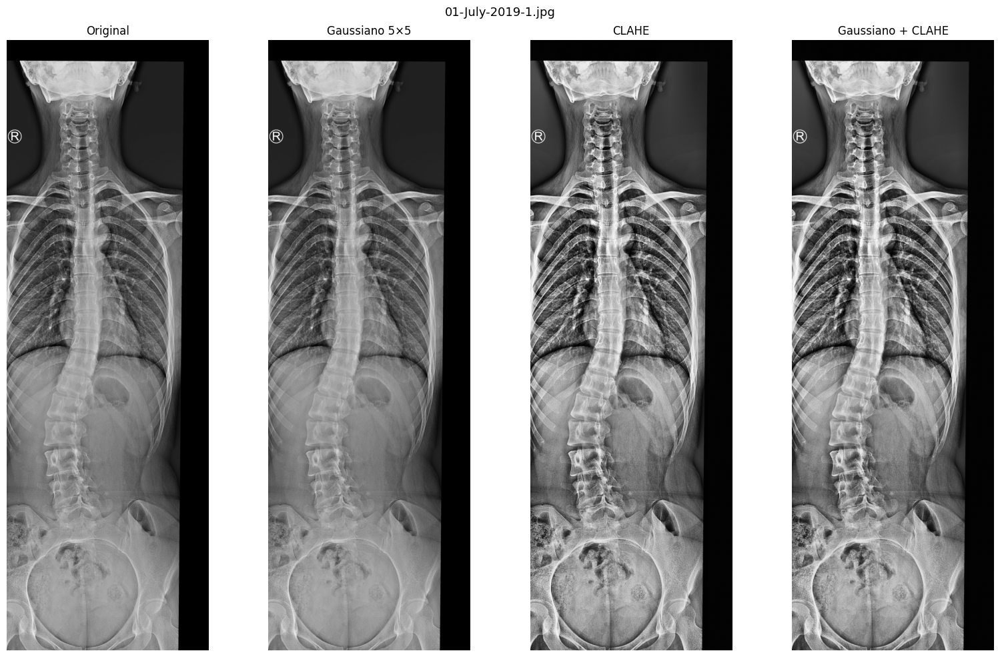

In [7]:
# 6. Comparación de preprocesamientos
INDICE = 0  # Podés cambiarlo por un número entre 0 y 97.

ruta = imagenes[INDICE]
img_original = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)

# Suavizado Gaussiano
img_gauss = cv2.GaussianBlur(
    img_original,
    (5, 5),
    sigmaX=0,
)

# CLAHE: contraste local con limitación de amplificación
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8),
)

img_clahe = clahe.apply(img_original)
img_gauss_clahe = clahe.apply(img_gauss)

comparaciones = {
    "Original": img_original,
    "Gaussiano 5×5": img_gauss,
    "CLAHE": img_clahe,
    "Gaussiano + CLAHE": img_gauss_clahe,
}

fig, axes = plt.subplots(1, 4, figsize=(16, 10))

for ax, (titulo, imagen) in zip(axes, comparaciones.items()):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

fig.suptitle(ruta.name, fontsize=13)
plt.tight_layout()
plt.show()

### Preprocesamiento

Se adopta un filtro Gaussiano de 5×5 seguido de CLAHE, con
clipLimit=2.0 y tileGridSize=(8, 8), como configuración inicial
del procesamiento.

El suavizado busca atenuar pequeñas variaciones de intensidad,
mientras que CLAHE busca mejorar el contraste local de las
estructuras vertebrales. Se presenta una comparación visual
con la imagen original y con cada operación por separado
para ilustrar sus efectos.

La utilidad de esta configuración se evaluará posteriormente
sobre el seguimiento de la trayectoria vertebral, considerando
también los casos de fallo.

#### Parámetros de CLAHE

- **`tileGridSize=(8, 8)`**: divide la imagen en una grilla de 8 filas y 8 columnas, formando 64 regiones. El contraste se ajusta localmente y los resultados se combinan mediante interpolación para evitar transiciones abruptas. Este parámetro indica la cantidad de regiones, no su tamaño en píxeles.

- **`clipLimit=2.0`**: establece el límite normalizado de recorte de los histogramas locales y controla la intensidad del realce. Limitar sus picos ayuda a evitar una amplificación excesiva del ruido. Valores mayores permiten un aumento más intenso del contraste; el valor 2.0 no significa que el contraste se duplique.

### Localización inicial de la columna

Se analiza una región central de la radiografía para reducir
la influencia de los bordes y de estructuras periféricas.

Dentro de esta región se calcula la media de intensidades
por columna de píxeles y se suaviza el perfil obtenido.
Su máximo se utiliza como una estimación inicial de la
posición horizontal de la columna vertebral.

Esta estimación no constituye una segmentación: otras
estructuras brillantes pueden desplazar el máximo. Por eso
se visualiza su posición sobre la radiografía antes de
utilizarla para el seguimiento.

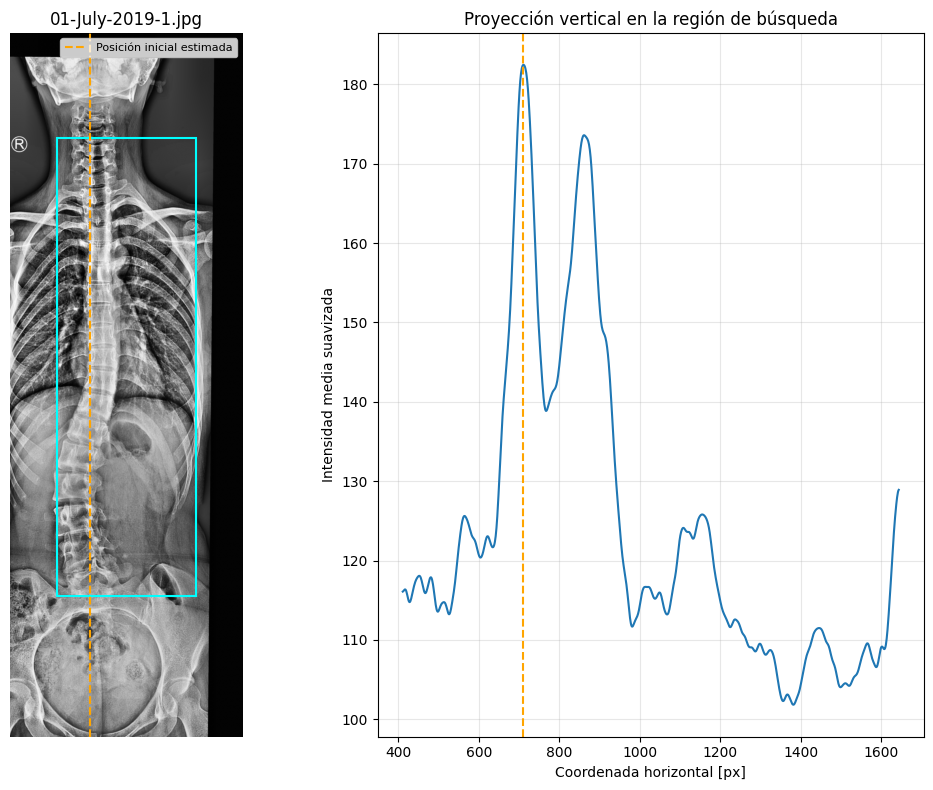

In [9]:
# 8. Estimación inicial mediante proyección vertical
INDICE = 0

ruta = imagenes[INDICE]
img_original = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
img_proc = preprocesar_imagen(img_original)

alto, ancho = img_proc.shape

# Región de búsqueda: parámetros iniciales.
x_ini = int(ancho * 0.20)
x_fin = int(ancho * 0.80)
y_ini = int(alto * 0.15)
y_fin = int(alto * 0.80)

zona = img_proc[y_ini:y_fin, x_ini:x_fin]

# Media por columna y suavizado del perfil.
perfil = zona.mean(axis=0)
perfil_suave = gaussian_filter1d(perfil, sigma=5)

x_centro = x_ini + int(np.argmax(perfil_suave))

fig, axes = plt.subplots(1, 2, figsize=(11, 8))

axes[0].imshow(img_proc, cmap="gray", vmin=0, vmax=255)
axes[0].add_patch(
    plt.Rectangle(
        (x_ini, y_ini),
        x_fin - x_ini,
        y_fin - y_ini,
        edgecolor="cyan",
        facecolor="none",
        linewidth=1.5,
    )
)
axes[0].axvline(
    x_centro,
    color="orange",
    linestyle="--",
    label="Posición inicial estimada",
)
axes[0].set_title(ruta.name)
axes[0].legend(fontsize=8)
axes[0].axis("off")

coordenadas_x = np.arange(x_ini, x_fin)
axes[1].plot(coordenadas_x, perfil_suave)
axes[1].axvline(x_centro, color="orange", linestyle="--")
axes[1].set_xlabel("Coordenada horizontal [px]")
axes[1].set_ylabel("Intensidad media suavizada")
axes[1].set_title("Proyección vertical en la región de búsqueda")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretación de la proyección vertical

Se realizó una proyección vertical de intensidades para obtener
una primera aproximación de la posición horizontal de la columna
vertebral y explorar si este criterio puede orientar su localización.

El rectángulo cian delimita la región de búsqueda. Dentro de ella
se calculó la intensidad media de cada columna de píxeles y se
suavizó el perfil resultante. La curva azul representa ese perfil,
mientras que la línea naranja indica la posición de su máximo.

El método se basa en que las estructuras óseas pueden generar
valores elevados de intensidad. Sin embargo, otras estructuras
anatómicas también contribuyen al perfil, por lo que su máximo
no identifica necesariamente el centro de la columna.

Esta estimación se utilizará como orientación inicial para
delimitar una región de interés. No identifica los platillos
vertebrales ni permite calcular por sí sola el ángulo de Cobb.

Deteccion de angulo de Cobb


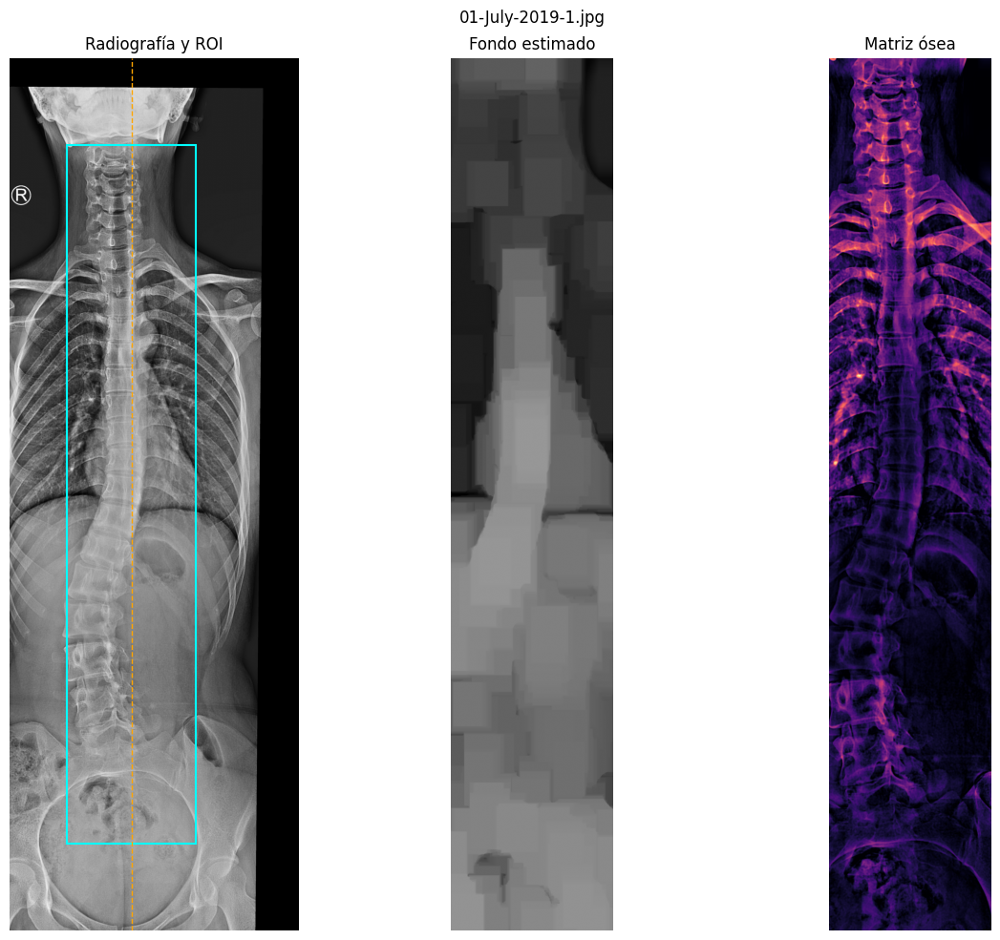

In [13]:
# 12. Aislamiento de la región de la columna y matriz ósea

def extraer_roi_hueso(img_gray):
    alto, ancho = img_gray.shape

    # Reducir el ruido granular de la radiografía.
    imagen_mediana = cv2.medianBlur(
        img_gray,
        9,
    )

    # Buscar la región con mayor acumulación de intensidad ósea.
    x_busqueda_0 = int(0.20 * ancho)
    x_busqueda_1 = int(0.80 * ancho)

    zona_central = imagen_mediana[
        :,
        x_busqueda_0:x_busqueda_1,
    ]

    suma_columnas = zona_central.sum(axis=0)

    suma_suavizada = gaussian_filter1d(
        suma_columnas.astype(float),
        sigma=5,
    )

    columna_pico = (
        x_busqueda_0
        + int(np.argmax(suma_suavizada))
    )

    # Región amplia para incluir posibles curvaturas laterales.
    ancho_roi = int(0.45 * ancho)

    x_min = max(
        0,
        columna_pico - ancho_roi // 2,
    )

    x_max = min(
        ancho,
        columna_pico + ancho_roi // 2,
    )

    y_min = int(0.10 * alto)
    y_max = int(0.90 * alto)

    roi_columna = imagen_mediana[
        y_min:y_max,
        x_min:x_max,
    ]

    # Apertura morfológica para estimar el fondo de baja frecuencia.
    ancho_kernel = max(3, int(0.08 * ancho))
    alto_kernel = max(3, int(0.04 * alto))

    kernel_fondo = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (ancho_kernel, alto_kernel),
    )

    fondo_macro = cv2.morphologyEx(
        roi_columna,
        cv2.MORPH_OPEN,
        kernel_fondo,
    )

    # Resta del fondo para conservar detalles óseos.
    matriz_osea = cv2.subtract(
        roi_columna,
        fondo_macro,
    )

    coordenadas_roi = (
        x_min,
        y_min,
        x_max,
        y_max,
    )

    return (
        roi_columna,
        fondo_macro,
        matriz_osea,
        coordenadas_roi,
        columna_pico,
    )


(
    roi_columna,
    fondo_macro,
    solo_hueso,
    roi_coords,
    columna_pico,
) = extraer_roi_hueso(img_original)

x_min, y_min, x_max, y_max = roi_coords

# Visualización del procedimiento.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 10),
)

axes[0].imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255,
)

axes[0].add_patch(
    plt.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        edgecolor="cyan",
        facecolor="none",
        linewidth=1.5,
    )
)

axes[0].axvline(
    columna_pico,
    color="orange",
    linestyle="--",
    linewidth=1,
)

axes[0].set_title("Radiografía y ROI")

axes[1].imshow(
    fondo_macro,
    cmap="gray",
    vmin=0,
    vmax=255,
)
axes[1].set_title("Fondo estimado")

axes[2].imshow(
    solo_hueso,
    cmap="magma",
)
axes[2].set_title("Matriz ósea")

for ax in axes:
    ax.axis("off")

plt.suptitle(ruta.name)
plt.tight_layout()
plt.show()

Se aplica un filtro de mediana para disminuir el ruido y se utiliza la suma de intensidades por columna para estimar una posición inicial de la columna vertebral. Alrededor de esta posición se define una región de interés amplia. Mediante una apertura morfológica se obtiene una aproximación del fondo de baja frecuencia, que contiene principalmente variaciones generales de iluminación y tejidos de gran tamaño. Finalmente, este fondo se resta de la región original para resaltar los detalles óseos. Esta etapa se realiza únicamente sobre la radiografía y no utiliza las anotaciones de referencia.

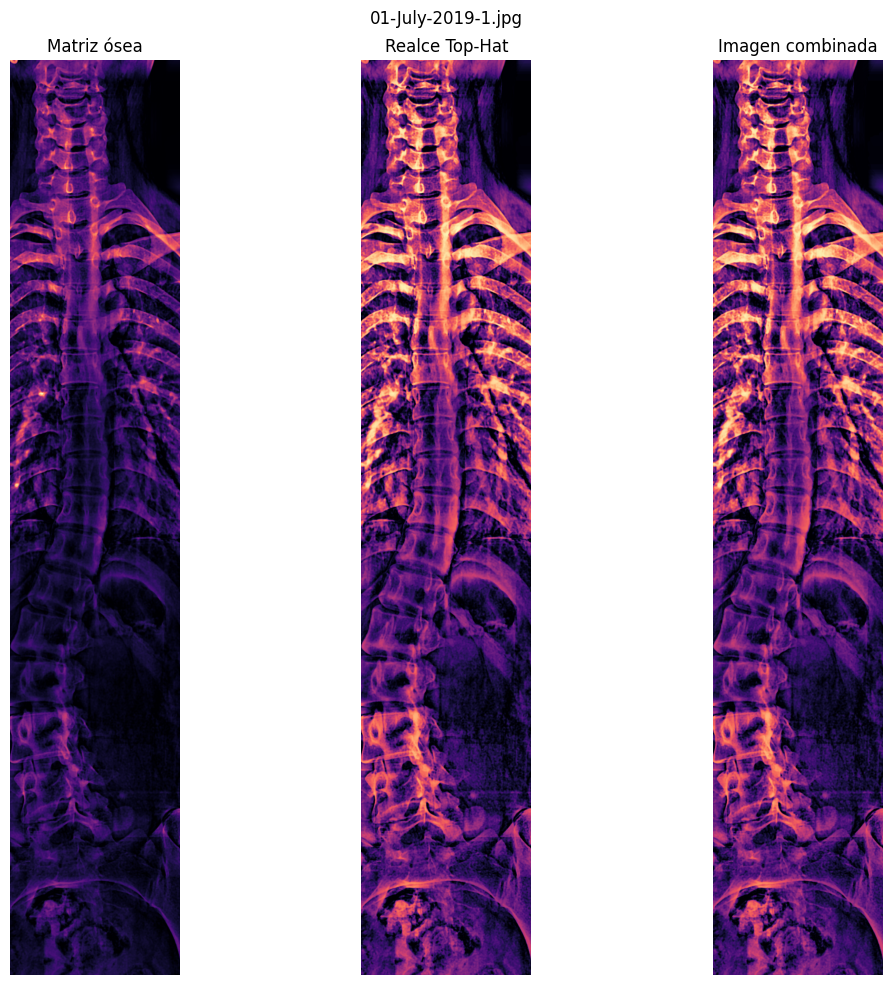

In [14]:
# 13. Realce de estructuras óseas y platillos

def realzar_estructuras(solo_hueso):
    alto_roi, ancho_roi = solo_hueso.shape

    # Aumentar el contraste local.
    clahe_oseo = cv2.createCLAHE(
        clipLimit=3.0,
        tileGridSize=(8, 8),
    )

    matriz_clahe = clahe_oseo.apply(
        solo_hueso
    )

    # Elemento estructurante para resaltar detalles óseos
    # menores que el fondo anatómico.
    ancho_tophat = max(3, ancho_roi // 4)
    alto_tophat = max(3, alto_roi // 14)

    kernel_tophat = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (ancho_tophat, alto_tophat),
    )

    realce_tophat = cv2.morphologyEx(
        matriz_clahe,
        cv2.MORPH_TOPHAT,
        kernel_tophat,
    )

    # Combinar el contraste local con el realce morfológico.
    base_osea = cv2.addWeighted(
        matriz_clahe,
        0.55,
        realce_tophat,
        0.45,
        0,
    )

    return (
        matriz_clahe,
        realce_tophat,
        base_osea,
    )


(
    matriz_clahe,
    realce_tophat,
    base_osea,
) = realzar_estructuras(solo_hueso)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 10),
)

axes[0].imshow(
    solo_hueso,
    cmap="magma",
)
axes[0].set_title("Matriz ósea")

axes[1].imshow(
    realce_tophat,
    cmap="magma",
)
axes[1].set_title("Realce Top-Hat")

axes[2].imshow(
    base_osea,
    cmap="magma",
)
axes[2].set_title("Imagen combinada")

for ax in axes:
    ax.axis("off")

plt.suptitle(ruta.name)
plt.tight_layout()
plt.show()

Sobre la matriz ósea se aplica CLAHE para aumentar el contraste local. Luego se utiliza una transformación Top-Hat, que resalta estructuras claras de menor tamaño que el elemento estructurante, entre ellas bordes y detalles de los cuerpos vertebrales. Finalmente, la imagen contrastada y el resultado de Top-Hat se combinan para formar una imagen base destinada al seguimiento de la columna y a la identificación de candidatos vertebrales.

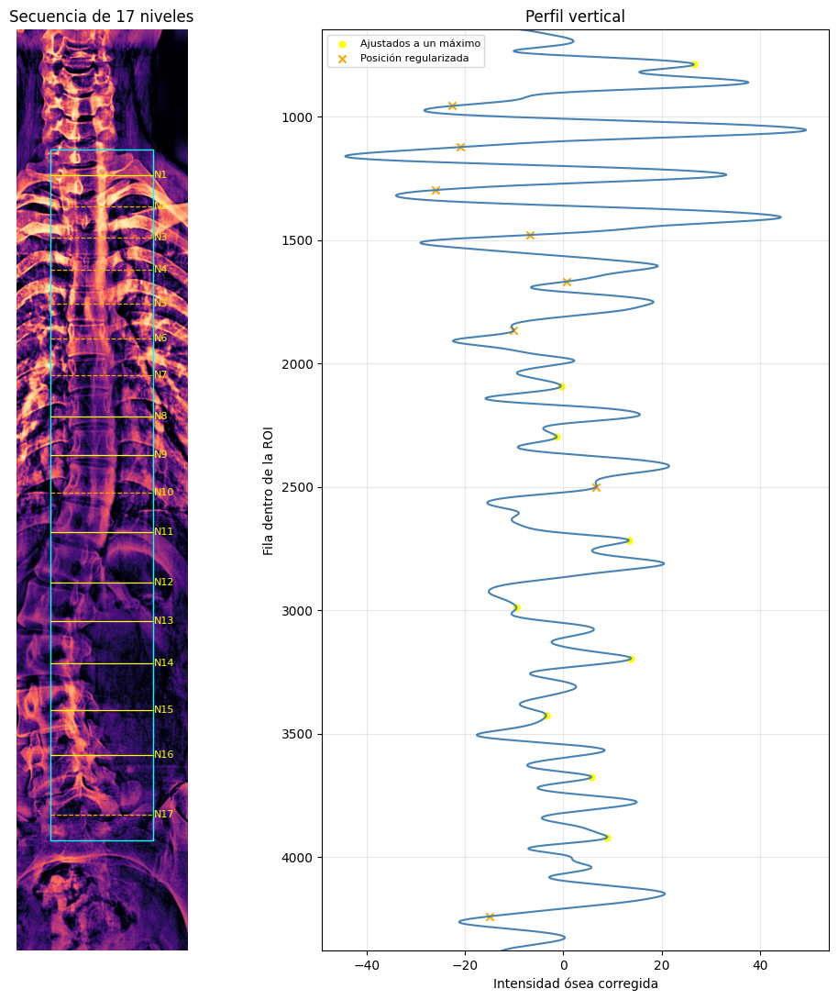

Niveles ajustados a máximos: 9
Niveles mantenidos por regularización: 8


In [15]:
# 14. Detección regularizada de 17 niveles vertebrales

from scipy.signal import find_peaks

alto_base, ancho_base = base_osea.shape

# Banda utilizada para calcular el perfil vertical.
x_perfil_0 = int(0.20 * ancho_base)
x_perfil_1 = int(0.80 * ancho_base)

banda_perfil = base_osea[
    :,
    x_perfil_0:x_perfil_1,
]

perfil_vertebral = banda_perfil.mean(
    axis=1
)

perfil_suave = gaussian_filter1d(
    perfil_vertebral,
    sigma=max(3, 0.003 * alto_base),
)

tendencia_perfil = gaussian_filter1d(
    perfil_suave,
    sigma=max(5, 0.035 * alto_base),
)

perfil_corregido = (
    perfil_suave - tendencia_perfil
)

# Obtener un conjunto amplio de máximos locales.
fila_valida_0 = int(0.13 * alto_base)
fila_valida_1 = int(0.88 * alto_base)

zona_valida = perfil_corregido[
    fila_valida_0:fila_valida_1
]

variabilidad = max(
    1e-6,
    1.4826 * np.median(
        np.abs(
            zona_valida
            - np.median(zona_valida)
        )
    ),
)

picos_locales, propiedades = find_peaks(
    zona_valida,
    distance=max(8, int(0.010 * alto_base)),
    prominence=0.08 * variabilidad,
)

picos_disponibles = (
    fila_valida_0 + picos_locales
)

prominencias = propiedades[
    "prominences"
]

# Secuencia anatómica esperada de 17 niveles.
NUMERO_NIVELES = 17

fila_inicial = 0.16 * alto_base
fila_final = 0.852 * alto_base

# La separación aumenta gradualmente hacia la región lumbar.
RELACION_SEPARACION = 1.70

primera_separacion = (
    2 * (fila_final - fila_inicial)
    / (
        (NUMERO_NIVELES - 1)
        * (1 + RELACION_SEPARACION)
    )
)

separaciones_esperadas = np.linspace(
    primera_separacion,
    RELACION_SEPARACION * primera_separacion,
    NUMERO_NIVELES - 1,
)

niveles_esperados = np.concatenate([
    [fila_inicial],
    fila_inicial
    + np.cumsum(separaciones_esperadas),
])

niveles_detectados = []
ajustado_por_perfil = []

for i, nivel_esperado in enumerate(
    niveles_esperados
):
    if i == 0:
        separacion_local = (
            separaciones_esperadas[0]
        )
    elif i == NUMERO_NIVELES - 1:
        separacion_local = (
            separaciones_esperadas[-1]
        )
    else:
        separacion_local = np.mean([
            separaciones_esperadas[i - 1],
            separaciones_esperadas[i],
        ])

    # Solo aceptar máximos próximos al nivel esperado.
    radio_ajuste = (
        0.20 * separacion_local
    )

    indices_cercanos = np.where(
        np.abs(
            picos_disponibles
            - nivel_esperado
        )
        <= radio_ajuste
    )[0]

    if len(indices_cercanos):
        distancias = np.abs(
            picos_disponibles[
                indices_cercanos
            ]
            - nivel_esperado
        )

        prominencias_locales = (
            prominencias[indices_cercanos]
        )

        prominencias_normalizadas = (
            prominencias_locales
            / (
                prominencias_locales.max()
                + 1e-9
            )
        )

        puntuacion = (
            -distancias / radio_ajuste
            + 0.15
            * prominencias_normalizadas
        )

        mejor_indice = indices_cercanos[
            np.argmax(puntuacion)
        ]

        nivel_final = float(
            picos_disponibles[mejor_indice]
        )

        ajustado = True

    else:
        # Mantener la posición regularizada si no hay
        # un máximo suficientemente próximo.
        nivel_final = float(
            nivel_esperado
        )

        ajustado = False

    niveles_detectados.append(
        nivel_final
    )

    ajustado_por_perfil.append(
        ajustado
    )

picos_vertebrales = np.rint(
    niveles_detectados
).astype(int)

ajustado_por_perfil = np.asarray(
    ajustado_por_perfil,
    dtype=bool,
)

# Visualización.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 11),
)

axes[0].imshow(
    base_osea,
    cmap="magma",
)

axes[0].add_patch(
    plt.Rectangle(
        (x_perfil_0, fila_valida_0),
        x_perfil_1 - x_perfil_0,
        fila_valida_1 - fila_valida_0,
        edgecolor="cyan",
        facecolor="none",
        linewidth=1,
    )
)

for i, (fila, ajustado) in enumerate(
    zip(
        picos_vertebrales,
        ajustado_por_perfil,
    ),
    start=1,
):
    axes[0].plot(
        [x_perfil_0, x_perfil_1],
        [fila, fila],
        color=(
            "yellow"
            if ajustado
            else "orange"
        ),
        linestyle=(
            "-"
            if ajustado
            else "--"
        ),
        linewidth=0.9,
    )

    axes[0].text(
        x_perfil_1 + 5,
        fila,
        f"N{i}",
        color="yellow",
        fontsize=8,
        verticalalignment="center",
    )

axes[0].set_title(
    "Secuencia de 17 niveles"
)
axes[0].axis("off")

filas = np.arange(alto_base)

axes[1].plot(
    perfil_corregido,
    filas,
    color="steelblue",
)

axes[1].scatter(
    perfil_corregido[
        picos_vertebrales[
            ajustado_por_perfil
        ]
    ],
    picos_vertebrales[
        ajustado_por_perfil
    ],
    color="yellow",
    s=25,
    label="Ajustados a un máximo",
)

axes[1].scatter(
    perfil_corregido[
        picos_vertebrales[
            ~ajustado_por_perfil
        ]
    ],
    picos_vertebrales[
        ~ajustado_por_perfil
    ],
    color="orange",
    marker="x",
    s=35,
    label="Posición regularizada",
)

axes[1].set_ylim(
    fila_valida_1,
    fila_valida_0,
)

axes[1].set_xlabel(
    "Intensidad ósea corregida"
)
axes[1].set_ylabel(
    "Fila dentro de la ROI"
)
axes[1].set_title(
    "Perfil vertical"
)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Niveles ajustados a máximos:",
    int(ajustado_por_perfil.sum()),
)

print(
    "Niveles mantenidos por regularización:",
    int((~ajustado_por_perfil).sum()),
)

Se establece una secuencia de 17 niveles cuya separación aumenta gradualmente hacia la región lumbar. Para cada posición esperada se busca un máximo cercano en el perfil óseo. El nivel se desplaza únicamente cuando existe un máximo dentro de una ventana limitada; en caso contrario se conserva la posición regularizada. Las líneas continuas indican niveles respaldados por un máximo próximo y las discontinuas corresponden a posiciones estimadas por la regularización anatómica.

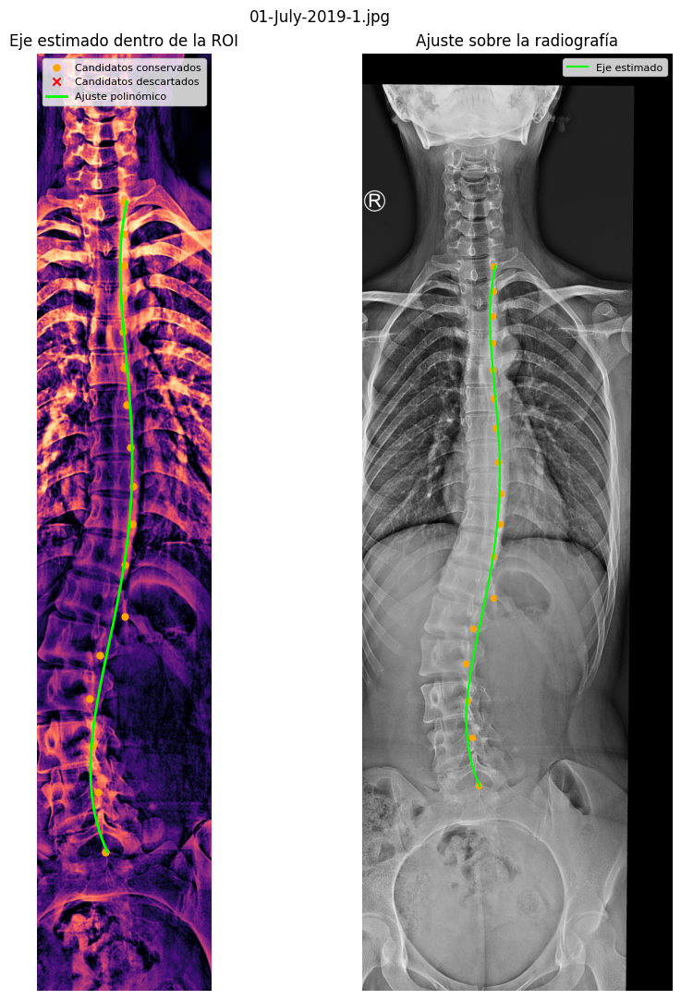

In [16]:
# 15. Centros candidatos y ajuste polinómico del eje

centros_candidatos = []

# Comenzar en el centro de la ROI.
x_anterior = ancho_base / 2

# Altura típica entre candidatos.
if len(picos_vertebrales) > 1:
    separacion_mediana = np.median(
        np.diff(picos_vertebrales)
    )
else:
    separacion_mediana = 0.05 * alto_base

for fila in picos_vertebrales:
    medio_alto = max(
        10,
        int(0.25 * separacion_mediana),
    )

    y0_local = max(
        0,
        int(fila - medio_alto),
    )

    y1_local = min(
        alto_base,
        int(fila + medio_alto),
    )

    radio_horizontal = int(
        0.15 * ancho_base
    )

    x0_local = max(
        0,
        int(x_anterior - radio_horizontal),
    )

    x1_local = min(
        ancho_base,
        int(x_anterior + radio_horizontal),
    )

    recorte_local = base_osea[
        y0_local:y1_local,
        x0_local:x1_local,
    ]

    perfil_horizontal = recorte_local.mean(
        axis=0
    )

    perfil_horizontal = gaussian_filter1d(
        perfil_horizontal,
        sigma=max(1, 0.012 * ancho_base),
    )

    coordenadas_x = np.arange(
        x0_local,
        x1_local,
    )

    amplitud = max(
        np.ptp(perfil_horizontal),
        1e-6,
    )

    distancia_previa = (
        np.abs(coordenadas_x - x_anterior)
        / max(radio_horizontal, 1)
    )

    # Favorecer intensidad alta sin permitir saltos grandes.
    puntuacion = (
        perfil_horizontal
        - 0.55 * amplitud * distancia_previa
    )

    x_candidato = float(
        coordenadas_x[np.argmax(puntuacion)]
    )

    centros_candidatos.append([
        x_candidato,
        float(fila),
    ])

    x_anterior = x_candidato

centros_candidatos = np.asarray(
    centros_candidatos,
    dtype=float,
)

# Ajuste polinómico solo si hay suficientes candidatos.
if len(centros_candidatos) < 5:
    raise ValueError(
        "No hay suficientes candidatos para ajustar el eje."
    )

y_centros = centros_candidatos[:, 1]
x_centros = centros_candidatos[:, 0]

# Primer ajuste de grado 4.
coeficientes_eje = np.polyfit(
    y_centros,
    x_centros,
    deg=4,
)

x_ajuste_centros = np.polyval(
    coeficientes_eje,
    y_centros,
)

# Rechazo sencillo de candidatos muy alejados del ajuste.
residuos = x_centros - x_ajuste_centros

mediana_residuos = np.median(residuos)

mad_residuos = max(
    1.0,
    1.4826 * np.median(
        np.abs(residuos - mediana_residuos)
    ),
)

candidatos_validos = (
    np.abs(residuos - mediana_residuos)
    <= 2.5 * mad_residuos
)

# Repetir el ajuste con los candidatos compatibles.
if candidatos_validos.sum() >= 5:
    coeficientes_eje = np.polyfit(
        y_centros[candidatos_validos],
        x_centros[candidatos_validos],
        deg=4,
    )

y_eje = np.arange(
    int(y_centros.min()),
    int(y_centros.max()) + 1,
)

x_eje = np.polyval(
    coeficientes_eje,
    y_eje,
)

# Visualización.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 11),
)

axes[0].imshow(
    base_osea,
    cmap="magma",
)

axes[0].scatter(
    x_centros[candidatos_validos],
    y_centros[candidatos_validos],
    color="orange",
    s=25,
    label="Candidatos conservados",
)

axes[0].scatter(
    x_centros[~candidatos_validos],
    y_centros[~candidatos_validos],
    color="red",
    marker="x",
    s=35,
    label="Candidatos descartados",
)

axes[0].plot(
    x_eje,
    y_eje,
    color="lime",
    linewidth=2,
    label="Ajuste polinómico",
)

axes[0].set_title(
    "Eje estimado dentro de la ROI"
)
axes[0].legend(fontsize=8)
axes[0].axis("off")

axes[1].imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255,
)

axes[1].scatter(
    x_min + x_centros[candidatos_validos],
    y_min + y_centros[candidatos_validos],
    color="orange",
    s=18,
)

axes[1].plot(
    x_min + x_eje,
    y_min + y_eje,
    color="lime",
    linewidth=1.6,
    label="Eje estimado",
)

axes[1].set_title(
    "Ajuste sobre la radiografía"
)
axes[1].legend(fontsize=8)
axes[1].axis("off")

plt.suptitle(ruta.name)
plt.tight_layout()
plt.show()

Para cada altura candidata se calcula un perfil horizontal dentro de una región local y se selecciona una posición de intensidad alta próxima al candidato anterior. Los centros obtenidos se utilizan para ajustar un polinomio de cuarto grado. Los puntos excesivamente alejados del primer ajuste se descartan mediante un criterio robusto basado en la desviación absoluta mediana y luego se repite el ajuste. El polinomio se representa únicamente dentro del intervalo cubierto por los candidatos para evitar extrapolaciones en zonas no analizadas.

,Nivel,x automático,y automático,x referencia,y referencia,Error horizontal [px],Error vertical [px],Error total [px]
0,N1,884.3,1410.0,761.3,1432.7,123.0,-22.7,125.0
1,N2,856.6,1578.0,778.1,1592.3,78.5,-14.3,79.7
2,N3,848.2,1745.0,789.5,1765.6,58.8,-20.6,62.3
3,N4,853.3,1919.0,797.5,1939.5,55.8,-20.5,59.4
4,N5,867.2,2101.0,786.7,2112.1,80.5,-11.1,81.3
5,N6,884.8,2290.0,788.2,2298.7,96.6,-8.7,97.0
6,N7,901.2,2487.0,794.2,2484.4,106.9,2.6,107.0
7,N8,911.6,2713.0,808.8,2672.7,102.8,40.3,110.4
8,N9,909.9,2919.0,819.6,2867.6,90.3,51.4,103.9
9,N10,896.1,3122.0,800.3,3069.3,95.9,52.7,109.4


Error horizontal absoluto medio: 105.2 px
Error vertical absoluto medio: 35.1 px
Error total medio: 113.5 px


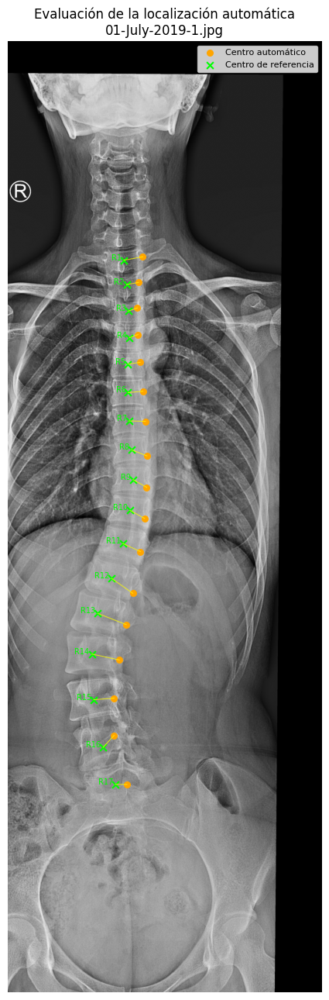

In [17]:
# Evaluación de los centros automáticos frente a la referencia

if len(picos_vertebrales) != len(vertebras_ref):
    raise ValueError(
        "La detección y la referencia deben tener "
        "la misma cantidad de niveles."
    )

# Centros de referencia en coordenadas globales.
centros_referencia = vertebras_ref.mean(
    axis=1
)

# Centros automáticos en coordenadas de la ROI.
centros_automaticos_roi = np.column_stack([
    np.polyval(
        coeficientes_eje,
        picos_vertebrales,
    ),
    picos_vertebrales,
])

# Convertir a coordenadas globales.
centros_automaticos = (
    centros_automaticos_roi
    + np.array([x_min, y_min])
)

error_horizontal = (
    centros_automaticos[:, 0]
    - centros_referencia[:, 0]
)

error_vertical = (
    centros_automaticos[:, 1]
    - centros_referencia[:, 1]
)

error_euclidiano = np.hypot(
    error_horizontal,
    error_vertical,
)

tabla_error_centros = pd.DataFrame({
    "Nivel": [
        f"N{i}"
        for i in range(1, 18)
    ],
    "x automático": centros_automaticos[:, 0],
    "y automático": centros_automaticos[:, 1],
    "x referencia": centros_referencia[:, 0],
    "y referencia": centros_referencia[:, 1],
    "Error horizontal [px]": error_horizontal,
    "Error vertical [px]": error_vertical,
    "Error total [px]": error_euclidiano,
})

display(
    tabla_error_centros.round(1)
)

print(
    "Error horizontal absoluto medio:",
    f"{np.mean(np.abs(error_horizontal)):.1f} px",
)

print(
    "Error vertical absoluto medio:",
    f"{np.mean(np.abs(error_vertical)):.1f} px",
)

print(
    "Error total medio:",
    f"{np.mean(error_euclidiano):.1f} px",
)

# Comparación visual.
fig, ax = plt.subplots(
    figsize=(7, 13),
)

ax.imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255,
)

for i in range(17):
    ax.plot(
        [
            centros_automaticos[i, 0],
            centros_referencia[i, 0],
        ],
        [
            centros_automaticos[i, 1],
            centros_referencia[i, 1],
        ],
        color="yellow",
        linewidth=0.8,
        alpha=0.7,
    )

ax.scatter(
    centros_automaticos[:, 0],
    centros_automaticos[:, 1],
    color="orange",
    s=30,
    label="Centro automático",
)

ax.scatter(
    centros_referencia[:, 0],
    centros_referencia[:, 1],
    color="lime",
    marker="x",
    s=40,
    label="Centro de referencia",
)

for i, centro in enumerate(
    centros_referencia,
    start=1,
):
    ax.text(
        centro[0] - 15,
        centro[1],
        f"R{i}",
        color="lime",
        fontsize=7,
        horizontalalignment="right",
    )

ax.set_title(
    "Evaluación de la localización automática\n"
    f"{ruta.name}"
)

ax.legend(fontsize=8)
ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
resumen_error = pd.Series({
    "Error horizontal medio [px]":
        np.mean(np.abs(error_horizontal)),

    "Error vertical medio [px]":
        np.mean(np.abs(error_vertical)),

    "Error total medio [px]":
        np.mean(error_euclidiano),

    "Error total mediano [px]":
        np.median(error_euclidiano),

    "Error máximo [px]":
        np.max(error_euclidiano),

    "Nivel con mayor error":
        f"N{np.argmax(error_euclidiano) + 1}"
})

display(resumen_error.to_frame("Valor").round(2))

,Valor
Error horizontal medio [px],105.185721
Error vertical medio [px],35.055706
Error total medio [px],113.497115
Error total mediano [px],106.978333
Error máximo [px],199.466777
Nivel con mayor error,N13


Aca compara con la referencia

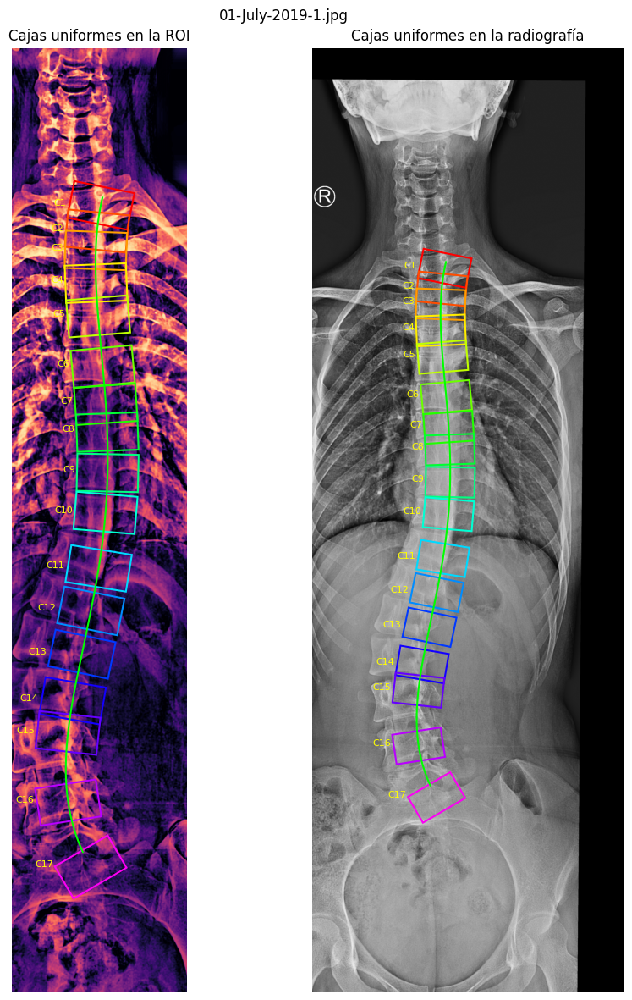

Altura uniforme: 197.0 px
Ancho uniforme: 323.4 px


In [19]:
# 16. Cajas candidatas con dimensiones uniformes

# Fronteras entre candidatos: mínimo del perfil
# situado entre dos máximos consecutivos.
fronteras_candidatas = []

if len(picos_vertebrales) < 2:
    raise ValueError(
        "Se necesitan al menos dos candidatos."
    )

# Frontera superior estimada.
primera_distancia = (
    picos_vertebrales[1]
    - picos_vertebrales[0]
)

fronteras_candidatas.append(
    max(
        0,
        int(
            picos_vertebrales[0]
            - primera_distancia / 2
        ),
    )
)

# Valles entre candidatos consecutivos.
for i in range(
    len(picos_vertebrales) - 1
):
    inicio = int(
        picos_vertebrales[i]
    )
    fin = int(
        picos_vertebrales[i + 1]
    )

    segmento = perfil_corregido[
        inicio:fin
    ]

    valle = (
        inicio + int(np.argmin(segmento))
    )

    fronteras_candidatas.append(
        valle
    )

# Frontera inferior estimada.
ultima_distancia = (
    picos_vertebrales[-1]
    - picos_vertebrales[-2]
)

fronteras_candidatas.append(
    min(
        alto_base - 1,
        int(
            picos_vertebrales[-1]
            + ultima_distancia / 2
        ),
    )
)

fronteras_candidatas = np.asarray(
    fronteras_candidatas,
    dtype=int,
)

# Altura uniforme y ancho fijo, como en el notebook anterior.
alturas_estimadas = np.diff(
    fronteras_candidatas
)

alto_uniforme = float(
    np.median(alturas_estimadas)
)

ancho_uniforme = float(
    0.35 * ancho_base
)

cajas_vertebrales_candidatas = []

for i in range(
    len(picos_vertebrales)
):
    frontera_superior = int(
        fronteras_candidatas[i]
    )

    frontera_inferior = int(
        fronteras_candidatas[i + 1]
    )

    centro_y = (
        frontera_superior
        + frontera_inferior
    ) / 2

    centro_x = float(
        np.polyval(
            coeficientes_eje,
            centro_y,
        )
    )

    # Evaluar el eje en los extremos de una caja uniforme.
    y_superior = max(
        0,
        centro_y - alto_uniforme / 2,
    )

    y_inferior = min(
        alto_base - 1,
        centro_y + alto_uniforme / 2,
    )

    x_superior = float(
        np.polyval(
            coeficientes_eje,
            y_superior,
        )
    )

    x_inferior = float(
        np.polyval(
            coeficientes_eje,
            y_inferior,
        )
    )

    dx_eje = (
        x_inferior - x_superior
    )

    dy_eje = (
        y_inferior - y_superior
    )

    angulo_caja = np.degrees(
        np.arctan2(
            -dx_eje,
            dy_eje,
        )
    )

    angulo_rad = np.radians(
        angulo_caja
    )

    direccion_horizontal = np.array([
        np.cos(angulo_rad),
        np.sin(angulo_rad),
    ])

    direccion_vertical = np.array([
        -np.sin(angulo_rad),
        np.cos(angulo_rad),
    ])

    centro = np.array([
        centro_x,
        centro_y,
    ])

    mitad_ancho = (
        ancho_uniforme / 2
    )

    mitad_alto = (
        alto_uniforme / 2
    )

    esquinas_roi = np.array([
        centro
        - mitad_ancho * direccion_horizontal
        - mitad_alto * direccion_vertical,

        centro
        + mitad_ancho * direccion_horizontal
        - mitad_alto * direccion_vertical,

        centro
        + mitad_ancho * direccion_horizontal
        + mitad_alto * direccion_vertical,

        centro
        - mitad_ancho * direccion_horizontal
        + mitad_alto * direccion_vertical,
    ])

    esquinas_globales = (
        esquinas_roi
        + np.array([x_min, y_min])
    )

    cajas_vertebrales_candidatas.append({
        "candidato": i + 1,
        "centro_roi": centro,
        "esquinas_roi": esquinas_roi,
        "esquinas_globales": esquinas_globales,
        "angulo_inicial": float(angulo_caja),
        "ancho": ancho_uniforme,
        "alto": alto_uniforme,
        "banda": (
            frontera_superior,
            frontera_inferior,
        ),
    })

# Visualización.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 12),
)

axes[0].imshow(
    base_osea,
    cmap="magma",
)

axes[1].imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255,
)

colores = plt.cm.hsv(
    np.linspace(
        0,
        0.85,
        len(cajas_vertebrales_candidatas),
    )
)

for caja, color in zip(
    cajas_vertebrales_candidatas,
    colores,
):
    esquinas_roi = caja[
        "esquinas_roi"
    ]

    esquinas_globales = caja[
        "esquinas_globales"
    ]

    axes[0].add_patch(
        plt.Polygon(
            esquinas_roi,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=1.5,
        )
    )

    axes[1].add_patch(
        plt.Polygon(
            esquinas_globales,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=1.5,
        )
    )

    axes[0].text(
        esquinas_roi[:, 0].min() - 5,
        esquinas_roi[:, 1].mean(),
        f"C{caja['candidato']}",
        color="yellow",
        fontsize=8,
        horizontalalignment="right",
    )

    axes[1].text(
        esquinas_globales[:, 0].min() - 8,
        esquinas_globales[:, 1].mean(),
        f"C{caja['candidato']}",
        color="yellow",
        fontsize=8,
        horizontalalignment="right",
    )

axes[0].plot(
    x_eje,
    y_eje,
    color="lime",
    linewidth=1.5,
)

axes[1].plot(
    x_min + x_eje,
    y_min + y_eje,
    color="lime",
    linewidth=1.5,
)

axes[0].set_title(
    "Cajas uniformes en la ROI"
)
axes[1].set_title(
    "Cajas uniformes en la radiografía"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(ruta.name)
plt.tight_layout()
plt.show()

print(
    "Altura uniforme:",
    round(alto_uniforme, 1),
    "px",
)

print(
    "Ancho uniforme:",
    round(ancho_uniforme, 1),
    "px",
)

Los mínimos del perfil situados entre máximos consecutivos se utilizan como fronteras aproximadas entre niveles. Para evitar cajas excesivamente grandes o pequeñas, todas adoptan la mediana de las alturas estimadas y un ancho equivalente al 35 % de la región de interés, siguiendo el criterio del análisis exploratorio anterior. La orientación de cada caja se obtiene a partir de la inclinación local del eje polinómico. Estas cajas continúan siendo candidatos geométricos y se evaluarán posteriormente frente a las anotaciones de referencia.

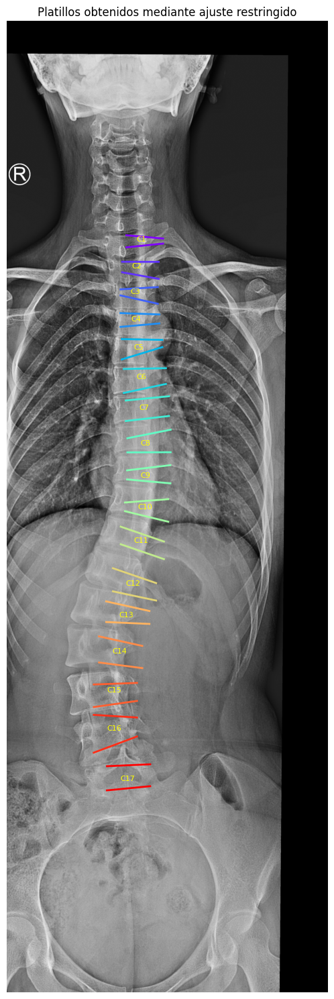

In [32]:
# 17. Ajuste restringido de los platillos vertebrales

# Normalización de la matriz ósea
imagen_ajuste = cv2.normalize(
    base_osea,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Suavizado para reducir respuestas producidas por ruido
imagen_suave = cv2.GaussianBlur(
    imagen_ajuste,
    (5, 5),
    0
)

# Gradientes horizontal y vertical
gradiente_x = cv2.Sobel(
    imagen_suave.astype(np.float32),
    cv2.CV_32F,
    1,
    0,
    ksize=3
)

gradiente_y = cv2.Sobel(
    imagen_suave.astype(np.float32),
    cv2.CV_32F,
    0,
    1,
    ksize=3
)

alto_roi, ancho_roi = imagen_ajuste.shape


def respuesta_recta(
    x_centro,
    y_recta,
    angulo,
    semiancho
):
    """
    Mide la intensidad del borde situado a lo largo
    de una recta candidata.
    """

    x = np.linspace(
        x_centro - semiancho,
        x_centro + semiancho,
        100
    )

    pendiente = np.tan(
        np.radians(angulo)
    )

    y = (
        y_recta
        + pendiente * (x - x_centro)
    )

    # Conservar solamente coordenadas interiores a la ROI
    validos = (
        (x >= 0)
        & (x < ancho_roi - 1)
        & (y >= 0)
        & (y < alto_roi - 1)
    )

    x = x[validos].astype(np.float32)
    y = y[validos].astype(np.float32)

    if len(x) < 30:
        return 0.0

    mapa_x = x.reshape(1, -1)
    mapa_y = y.reshape(1, -1)

    gx = cv2.remap(
        gradiente_x,
        mapa_x,
        mapa_y,
        cv2.INTER_LINEAR
    ).ravel()

    gy = cv2.remap(
        gradiente_y,
        mapa_x,
        mapa_y,
        cv2.INTER_LINEAR
    ).ravel()

    theta = np.radians(angulo)

    # Componente del gradiente perpendicular a la recta
    respuesta = np.abs(
        -np.sin(theta) * gx
        + np.cos(theta) * gy
    )

    # Limitar bordes aislados excesivamente intensos
    limite = np.percentile(
        respuesta,
        90
    )

    respuesta = np.clip(
        respuesta,
        0,
        limite
    )

    return float(
        np.mean(respuesta)
    )


def ajustar_platillo(
    x_centro,
    y_esperado,
    angulo_inicial,
    separacion,
    semiancho,
    peso_angulo
):
    """
    Busca el platillo con mayor respuesta dentro de una
    región limitada alrededor de su posición esperada.
    """

    # Posiciones verticales candidatas
    posiciones = np.linspace(
        y_esperado - 0.10 * separacion,
        y_esperado + 0.10 * separacion,
        13
    )

    # Orientaciones candidatas
    angulos = np.linspace(
        angulo_inicial - 12,
        angulo_inicial + 12,
        25
    )

    candidatos = []

    for y_candidato in posiciones:
        for angulo in angulos:

            respuesta = respuesta_recta(
                x_centro,
                y_candidato,
                angulo,
                semiancho
            )

            candidatos.append([
                respuesta,
                y_candidato,
                angulo
            ])

    candidatos = np.asarray(
        candidatos,
        dtype=float
    )

    respuestas = candidatos[:, 0]

    respuestas_normalizadas = (
        respuestas - respuestas.min()
    ) / (
        np.ptp(respuestas) + 1e-8
    )

    # Penalización por alejarse verticalmente
    penalizacion_y = (
        np.abs(
            candidatos[:, 1] - y_esperado
        )
        / (0.10 * separacion)
    )

    # Penalización por cambiar demasiado la orientación
    penalizacion_angulo = (
        np.abs(
            candidatos[:, 2] - angulo_inicial
        )
        / 12
    )

    puntuacion = (
        respuestas_normalizadas
        - 0.22 * penalizacion_y
        - peso_angulo * penalizacion_angulo
    )

    mejor_indice = int(
        np.argmax(puntuacion)
    )

    y_final = candidatos[
        mejor_indice,
        1
    ]

    angulo_final = candidatos[
        mejor_indice,
        2
    ]

    x_linea = np.array([
        x_centro - semiancho,
        x_centro + semiancho
    ])

    y_linea = (
        y_final
        + np.tan(
            np.radians(angulo_final)
        )
        * (x_linea - x_centro)
    )

    recta = np.column_stack([
        x_linea,
        y_linea
    ])

    return recta, float(angulo_final)


platillos_superiores = []
platillos_inferiores = []

angulos_superiores = []
angulos_inferiores = []

cantidad_niveles = len(
    picos_vertebrales
)

for i, y_centro in enumerate(
    picos_vertebrales
):
    # Separación vertical local entre vértebras
    if i == 0:
        separacion = (
            picos_vertebrales[1]
            - picos_vertebrales[0]
        )

    elif i == cantidad_niveles - 1:
        separacion = (
            picos_vertebrales[-1]
            - picos_vertebrales[-2]
        )

    else:
        separacion = (
            picos_vertebrales[i + 1]
            - picos_vertebrales[i - 1]
        ) / 2

    x_centro = float(
        np.polyval(
            coeficientes_eje,
            y_centro
        )
    )

    # Calcular la inclinación local utilizando niveles vecinos
    if i == 0:
        indice_1 = 0
        indice_2 = min(
            2,
            cantidad_niveles - 1
        )

    elif i == cantidad_niveles - 1:
        indice_1 = max(
            0,
            cantidad_niveles - 3
        )
        indice_2 = cantidad_niveles - 1

    else:
        indice_1 = i - 1
        indice_2 = i + 1

    y_vecino_1 = float(
        picos_vertebrales[indice_1]
    )

    y_vecino_2 = float(
        picos_vertebrales[indice_2]
    )

    x_vecino_1 = float(
        np.polyval(
            coeficientes_eje,
            y_vecino_1
        )
    )

    x_vecino_2 = float(
        np.polyval(
            coeficientes_eje,
            y_vecino_2
        )
    )

    dx_dy = (
        x_vecino_2 - x_vecino_1
    ) / (
        y_vecino_2 - y_vecino_1
        + 1e-8
    )

    # El platillo se espera perpendicular al eje local
    angulo_inicial = np.degrees(
        np.arctan(-dx_dy)
    )

    angulo_inicial = float(
        np.clip(
            angulo_inicial,
            -25,
            25
        )
    )

    # Mayor restricción en la región superior para evitar
    # falsas curvas causadas por costillas y clavículas
    if i < 7:
        peso_angulo = 0.25
    else:
        peso_angulo = 0.12

    semiancho = min(
        0.15 * ancho_roi,
        0.70 * separacion
    )

    y_superior_esperado = (
        y_centro
        - 0.23 * separacion
    )

    y_inferior_esperado = (
        y_centro
        + 0.23 * separacion
    )

    superior, angulo_sup = ajustar_platillo(
        x_centro,
        y_superior_esperado,
        angulo_inicial,
        separacion,
        semiancho,
        peso_angulo
    )

    inferior, angulo_inf = ajustar_platillo(
        x_centro,
        y_inferior_esperado,
        angulo_inicial,
        separacion,
        semiancho,
        peso_angulo
    )

    platillos_superiores.append(
        superior
    )

    platillos_inferiores.append(
        inferior
    )

    angulos_superiores.append(
        angulo_sup
    )

    angulos_inferiores.append(
        angulo_inf
    )


# Convertir las listas de ángulos en arreglos
angulos_superiores = np.asarray(
    angulos_superiores,
    dtype=float
)

angulos_inferiores = np.asarray(
    angulos_inferiores,
    dtype=float
)


# Visualización de los platillos
fig, ax = plt.subplots(
    figsize=(7, 15)
)

ax.imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255
)

colores = plt.cm.rainbow(
    np.linspace(
        0,
        1,
        cantidad_niveles
    )
)

for i, (
    superior,
    inferior,
    color
) in enumerate(
    zip(
        platillos_superiores,
        platillos_inferiores,
        colores
    )
):
    ax.plot(
        superior[:, 0] + x_min,
        superior[:, 1] + y_min,
        color=color,
        linewidth=2
    )

    ax.plot(
        inferior[:, 0] + x_min,
        inferior[:, 1] + y_min,
        color=color,
        linewidth=2
    )

    x_texto = (
        np.polyval(
            coeficientes_eje,
            picos_vertebrales[i]
        )
        + x_min
    )

    ax.text(
        x_texto - 55,
        picos_vertebrales[i] + y_min,
        f"C{i + 1}",
        color="yellow",
        fontsize=8
    )

ax.set_title(
    "Platillos obtenidos mediante ajuste restringido"
)

ax.axis("off")

plt.tight_layout()
plt.show()

La transformada de Hough generó falsas detecciones debido a la presencia de costillas y otros bordes aproximadamente rectos. Por este motivo, se utilizó un ajuste restringido de rectas basado en el gradiente de la imagen. Para cada nivel, la orientación inicial se estima a partir del desplazamiento del eje entre vértebras vecinas, evitando la inestabilidad del polinomio en los extremos. Alrededor de las posiciones esperadas de los platillos superior e inferior se prueban pequeñas variaciones de posición e inclinación. Finalmente, se selecciona la recta con mayor respuesta de borde, penalizando desplazamientos excesivos respecto de la posición y orientación iniciales. El procedimiento utiliza únicamente la radiografía procesada.

,Nivel,Confianza superior,Confianza inferior,Altura relativa,Diferencia angular (°),Calidad
0,C1,5.99,4.74,0.33,11.0,Alta
1,C2,5.54,4.02,0.53,10.0,Alta
2,C3,12.91,0.68,0.43,16.0,Media
3,C4,4.50,0.91,0.41,7.0,Media
4,C5,6.75,4.52,0.48,18.0,Baja
5,C6,5.25,1.10,0.66,11.0,Alta
6,C7,2.20,4.16,0.61,1.0,Alta
7,C8,15.66,3.43,0.54,11.0,Alta
8,C9,7.61,6.49,0.43,12.0,Alta
9,C10,7.45,9.66,0.48,18.0,Baja


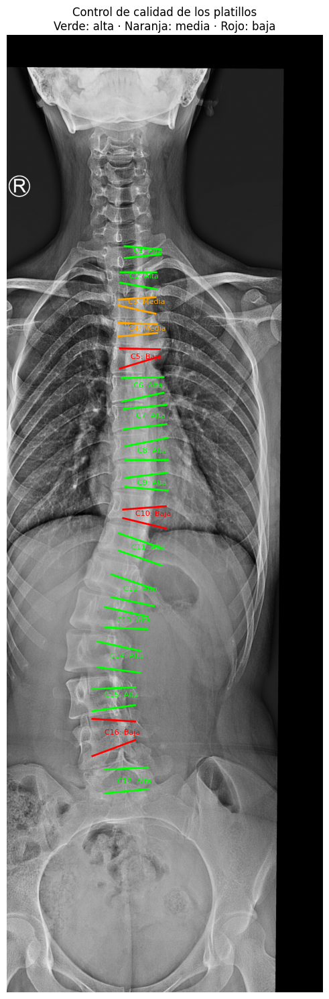

Platillos aceptados: 14 de 17


In [33]:
# 18. Control de calidad de los platillos detectados

resultados_calidad = []
platillos_validos = []

def separacion_local(indice):
    if indice == 0:
        return picos_vertebrales[1] - picos_vertebrales[0]

    if indice == len(picos_vertebrales) - 1:
        return picos_vertebrales[-1] - picos_vertebrales[-2]

    return (
        picos_vertebrales[indice + 1] -
        picos_vertebrales[indice - 1]
    ) / 2


def confianza_de_recta(recta, angulo, x_centro, separacion):
    """
    Compara la respuesta de la recta detectada con rectas paralelas
    ubicadas en posiciones verticales cercanas.
    """

    y_recta = np.mean(recta[:, 1])
    semiancho = abs(recta[1, 0] - recta[0, 0]) / 2

    respuesta_detectada = respuesta_recta(
        x_centro,
        y_recta,
        angulo,
        semiancho
    )

    desplazamientos = np.linspace(
        -0.18 * separacion,
         0.18 * separacion,
        19
    )

    respuestas_vecinas = []

    for desplazamiento in desplazamientos:
        # No se incluye la posición de la propia recta
        if abs(desplazamiento) < 0.035 * separacion:
            continue

        respuestas_vecinas.append(
            respuesta_recta(
                x_centro,
                y_recta + desplazamiento,
                angulo,
                semiancho
            )
        )

    respuestas_vecinas = np.asarray(respuestas_vecinas)

    mediana_vecinas = np.median(respuestas_vecinas)

    mad = np.median(
        np.abs(respuestas_vecinas - mediana_vecinas)
    )

    confianza = (
        respuesta_detectada - mediana_vecinas
    ) / (1.4826 * mad + 1e-8)

    return float(confianza)


for i in range(len(picos_vertebrales)):

    separacion = separacion_local(i)

    x_centro = float(
        np.polyval(
            coeficientes_eje,
            picos_vertebrales[i]
        )
    )

    superior = platillos_superiores[i]
    inferior = platillos_inferiores[i]

    confianza_sup = confianza_de_recta(
        superior,
        angulos_superiores[i],
        x_centro,
        separacion
    )

    confianza_inf = confianza_de_recta(
        inferior,
        angulos_inferiores[i],
        x_centro,
        separacion
    )

    altura_cuerpo = (
        np.mean(inferior[:, 1]) -
        np.mean(superior[:, 1])
    )

    altura_relativa = altura_cuerpo / separacion

    diferencia_angular = abs(
        angulos_superiores[i] -
        angulos_inferiores[i]
    )

    confianza_minima = min(
        confianza_sup,
        confianza_inf
    )

    geometria_valida = (
        0.28 <= altura_relativa <= 0.70
        and diferencia_angular <= 16
    )

    if confianza_minima >= 1.0 and geometria_valida:
        calidad = "Alta"
        valido = True

    elif confianza_minima >= 0.0 and geometria_valida:
        calidad = "Media"
        valido = True

    else:
        calidad = "Baja"
        valido = False

    platillos_validos.append(valido)

    resultados_calidad.append({
        "Nivel": f"C{i + 1}",
        "Confianza superior": confianza_sup,
        "Confianza inferior": confianza_inf,
        "Altura relativa": altura_relativa,
        "Diferencia angular (°)": diferencia_angular,
        "Calidad": calidad
    })


tabla_calidad = pd.DataFrame(resultados_calidad)

display(
    tabla_calidad.round({
        "Confianza superior": 2,
        "Confianza inferior": 2,
        "Altura relativa": 2,
        "Diferencia angular (°)": 2
    })
)


# Visualización según la calidad
fig, ax = plt.subplots(figsize=(7, 15))
ax.imshow(img_original, cmap="gray")

colores_calidad = {
    "Alta": "lime",
    "Media": "orange",
    "Baja": "red"
}

for i, resultado in enumerate(resultados_calidad):

    color = colores_calidad[resultado["Calidad"]]

    superior = platillos_superiores[i]
    inferior = platillos_inferiores[i]

    ax.plot(
        superior[:, 0] + x_min,
        superior[:, 1] + y_min,
        color=color,
        linewidth=2
    )

    ax.plot(
        inferior[:, 0] + x_min,
        inferior[:, 1] + y_min,
        color=color,
        linewidth=2
    )

    x_texto = (
        np.polyval(
            coeficientes_eje,
            picos_vertebrales[i]
        )
        + x_min - 60
    )

    y_texto = picos_vertebrales[i] + y_min

    ax.text(
        x_texto,
        y_texto,
        f"C{i + 1}: {resultado['Calidad']}",
        color=color,
        fontsize=8
    )

ax.set_title(
    "Control de calidad de los platillos\n"
    "Verde: alta · Naranja: media · Rojo: baja"
)
ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "Platillos aceptados:",
    int(np.sum(platillos_validos)),
    "de",
    len(platillos_validos)
)

Se compara la respuesta de cada platillo con la obtenida en rectas paralelas cercanas. También se controla la separación entre los platillos y la diferencia entre sus inclinaciones. Las detecciones se clasifican con calidad alta, media o baja. Este control permite excluir resultados poco confiables antes de seleccionar las vértebras límite y calcular el ángulo de Cobb.

Los umbrales empleados constituyen valores iniciales de control geométrico y estadístico. No representan criterios clínicos de confiabilidad. Posteriormente serán calibrados mediante la comparación entre los resultados automáticos y las anotaciones de referencia, utilizadas únicamente para la evaluación del procesamiento.

,Nivel,Ángulo medido (°),Ángulo suavizado (°),Aceptado
0,C1,-0.36,0.49,True
1,C2,5.14,3.69,True
2,C3,4.56,3.82,True
3,C4,-1.55,-0.45,True
4,C5,-7.86,-4.60,False
5,C6,-6.53,-6.04,True
6,C7,-6.12,-6.74,True
7,C8,-5.66,-5.35,True
8,C9,-0.83,-0.34,True
9,C10,4.62,9.78,False


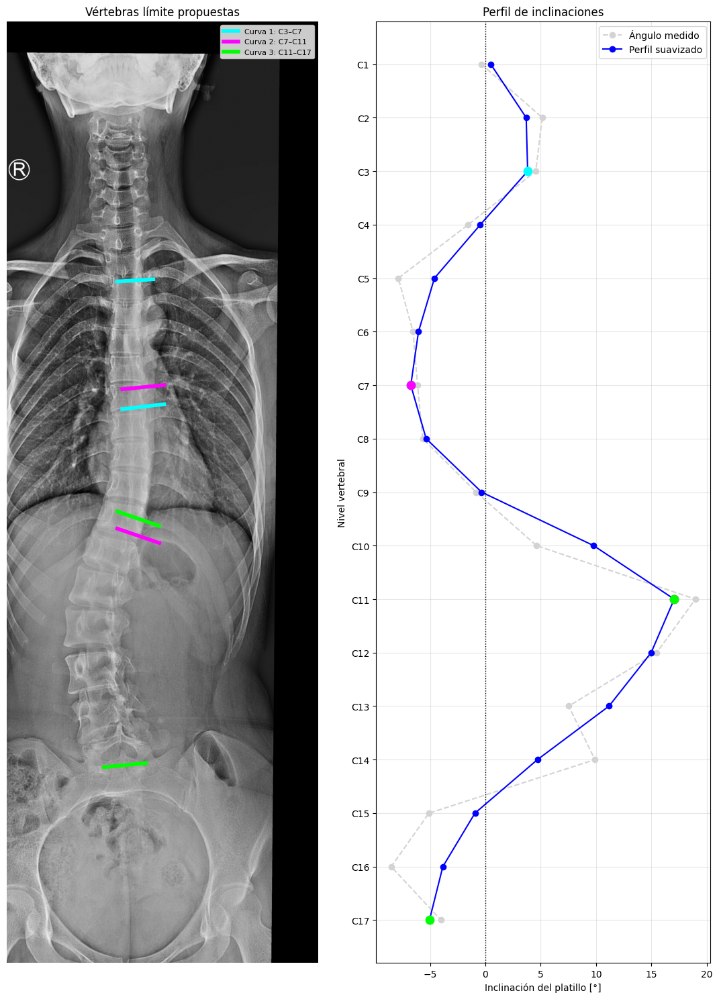

Curvas candidatas encontradas:
Curva 1: C3 a C7
Curva 2: C7 a C11
Curva 3: C11 a C17


In [34]:
# 19. Perfil de inclinaciones y selección de vértebras límite

from scipy.signal import savgol_filter, find_peaks

cantidad_vertebras = len(picos_vertebrales)

# Inclinación representativa de cada cuerpo vertebral
# Se combinan los ángulos de sus platillos superior e inferior.
angulos_vertebrales = []

for angulo_sup, angulo_inf in zip(
    angulos_superiores,
    angulos_inferiores
):
    # Media circular para orientaciones de rectas
    angulos_radianes = np.radians(
        [angulo_sup, angulo_inf]
    )

    seno_medio = np.mean(
        np.sin(2 * angulos_radianes)
    )

    coseno_medio = np.mean(
        np.cos(2 * angulos_radianes)
    )

    angulo_medio = 0.5 * np.degrees(
        np.arctan2(seno_medio, coseno_medio)
    )

    angulos_vertebrales.append(angulo_medio)

angulos_vertebrales = np.asarray(angulos_vertebrales)
validos = np.asarray(platillos_validos, dtype=bool)

# Si el control de calidad rechazó demasiados niveles,
# se mantienen todos solamente para poder visualizar el perfil.
if validos.sum() < 4:
    print(
        "Aviso: hay menos de cuatro niveles aceptados. "
        "Se visualizarán todos como candidatos."
    )
    validos[:] = True


# Interpolación de niveles rechazados para construir un perfil continuo
indices = np.arange(cantidad_vertebras)
indices_validos = indices[validos]

angulos_interpolados = np.interp(
    indices,
    indices_validos,
    angulos_vertebrales[validos]
)

# Suavizado leve del perfil angular
if cantidad_vertebras >= 5:
    angulos_suavizados = savgol_filter(
        angulos_interpolados,
        window_length=5,
        polyorder=2,
        mode="interp"
    )
else:
    angulos_suavizados = angulos_interpolados.copy()


# Búsqueda de máximos y mínimos del perfil
prominencia = max(
    1.5,
    0.12 * np.ptp(angulos_suavizados)
)

maximos, _ = find_peaks(
    angulos_suavizados,
    prominence=prominencia,
    distance=2
)

minimos, _ = find_peaks(
    -angulos_suavizados,
    prominence=prominencia,
    distance=2
)

# También se consideran los extremos superior e inferior
extremos = np.unique(
    np.concatenate([
        [0],
        maximos,
        minimos,
        [cantidad_vertebras - 1]
    ])
)


def nivel_valido_mas_cercano(indice):
    """Busca el nivel aceptado más próximo al extremo detectado."""

    distancias = np.abs(indices_validos - indice)
    return int(indices_validos[np.argmin(distancias)])


# Se forman curvas entre extremos consecutivos con inclinaciones opuestas
curvas_candidatas = []
cambio_angular_minimo = 5.0

for extremo_1, extremo_2 in zip(
    extremos[:-1],
    extremos[1:]
):
    angulo_1 = angulos_suavizados[extremo_1]
    angulo_2 = angulos_suavizados[extremo_2]

    tienen_signo_opuesto = (
        angulo_1 * angulo_2 <= 0
    )

    cambio_angular = abs(angulo_2 - angulo_1)

    if (
        tienen_signo_opuesto
        and cambio_angular >= cambio_angular_minimo
    ):
        limite_superior = nivel_valido_mas_cercano(extremo_1)
        limite_inferior = nivel_valido_mas_cercano(extremo_2)

        if limite_superior > limite_inferior:
            limite_superior, limite_inferior = (
                limite_inferior,
                limite_superior
            )

        if limite_superior != limite_inferior:
            par = (limite_superior, limite_inferior)

            if par not in curvas_candidatas:
                curvas_candidatas.append(par)


# Respaldo si no aparecen extremos internos claros
if len(curvas_candidatas) == 0:
    indice_maximo = nivel_valido_mas_cercano(
        int(np.argmax(angulos_suavizados))
    )

    indice_minimo = nivel_valido_mas_cercano(
        int(np.argmin(angulos_suavizados))
    )

    limite_superior = min(indice_maximo, indice_minimo)
    limite_inferior = max(indice_maximo, indice_minimo)

    if limite_superior != limite_inferior:
        curvas_candidatas.append(
            (limite_superior, limite_inferior)
        )


# Tabla de inclinaciones
tabla_inclinaciones = pd.DataFrame({
    "Nivel": [f"C{i + 1}" for i in indices],
    "Ángulo medido (°)": angulos_vertebrales,
    "Ángulo suavizado (°)": angulos_suavizados,
    "Aceptado": validos
})

display(tabla_inclinaciones.round(2))


# Visualización
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 15),
    gridspec_kw={"width_ratios": [1, 1]}
)

# Radiografía
axes[0].imshow(img_original, cmap="gray")

colores_curvas = [
    "cyan", "magenta", "lime", "orange"
]

for numero, (sup, inf) in enumerate(curvas_candidatas):

    color = colores_curvas[
        numero % len(colores_curvas)
    ]

    platillo_superior = platillos_superiores[sup]
    platillo_inferior = platillos_inferiores[inf]

    axes[0].plot(
        platillo_superior[:, 0] + x_min,
        platillo_superior[:, 1] + y_min,
        color=color,
        linewidth=4,
        label=(
            f"Curva {numero + 1}: "
            f"C{sup + 1}–C{inf + 1}"
        )
    )

    axes[0].plot(
        platillo_inferior[:, 0] + x_min,
        platillo_inferior[:, 1] + y_min,
        color=color,
        linewidth=4
    )

axes[0].set_title("Vértebras límite propuestas")
axes[0].legend(fontsize=8)
axes[0].axis("off")


# Perfil de inclinaciones
axes[1].plot(
    angulos_vertebrales,
    indices,
    "o--",
    color="lightgray",
    label="Ángulo medido"
)

axes[1].plot(
    angulos_suavizados,
    indices,
    "o-",
    color="blue",
    label="Perfil suavizado"
)

axes[1].axvline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

for numero, (sup, inf) in enumerate(curvas_candidatas):

    color = colores_curvas[
        numero % len(colores_curvas)
    ]

    axes[1].scatter(
        [angulos_suavizados[sup],
         angulos_suavizados[inf]],
        [sup, inf],
        color=color,
        s=80,
        zorder=5
    )

axes[1].set_yticks(indices)
axes[1].set_yticklabels(
    [f"C{i + 1}" for i in indices]
)
axes[1].invert_yaxis()
axes[1].set_xlabel("Inclinación del platillo [°]")
axes[1].set_ylabel("Nivel vertebral")
axes[1].set_title("Perfil de inclinaciones")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


print("Curvas candidatas encontradas:")

for numero, (sup, inf) in enumerate(
    curvas_candidatas,
    start=1
):
    print(
        f"Curva {numero}: "
        f"C{sup + 1} a C{inf + 1}"
    )

Se obtiene una inclinación representativa para cada vértebra combinando sus platillos superior e inferior. El perfil angular se suaviza para reducir variaciones aisladas y se buscan máximos y mínimos consecutivos con inclinaciones opuestas. Estos extremos permiten proponer las vértebras que limitan cada curva. El cambio mínimo de 5° se utiliza para detectar curvas candidatas y todavía no corresponde al umbral diagnóstico de escoliosis.

,Curva,Nivel superior,Nivel inferior,Ángulo superior (°),Ángulo inferior (°),Ángulo de Cobb (°),Clasificación
0,1,N3,N7,-3.44,-6.62,3.18,Inferior al umbral de 10°
1,2,N7,N11,-5.62,18.97,24.60,Leve
2,3,N11,N17,18.97,-5.51,24.48,Leve


Curva principal: N7–N11
Ángulo de Cobb: 24.60°
Clasificación: Leve


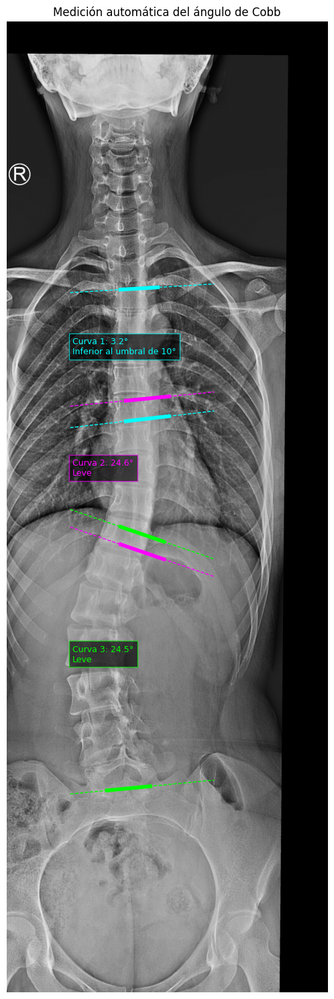

In [35]:
# 20. Cálculo del ángulo de Cobb y clasificación de gravedad

def angulo_entre_rectas(angulo_1, angulo_2):
    """Calcula el menor ángulo entre dos rectas."""

    diferencia = abs(angulo_1 - angulo_2) % 180
    return min(diferencia, 180 - diferencia)


def clasificar_cobb(angulo_cobb):
    """
    Clasificación basada en Hong et al. (2017).
    Se utiliza el valor sin redondear.
    """

    if angulo_cobb < 10:
        return "Inferior al umbral de 10°"

    elif angulo_cobb < 25:
        return "Leve"

    elif angulo_cobb < 40:
        return "Moderada"

    else:
        return "Severa"


resultados_cobb = []

for numero, (limite_sup, limite_inf) in enumerate(
    curvas_candidatas,
    start=1
):
    # Para Cobb se utiliza:
    # - platillo superior de la vértebra superior
    # - platillo inferior de la vértebra inferior
    angulo_superior = float(
        angulos_superiores[limite_sup]
    )

    angulo_inferior = float(
        angulos_inferiores[limite_inf]
    )

    cobb = angulo_entre_rectas(
        angulo_superior,
        angulo_inferior
    )

    gravedad = clasificar_cobb(cobb)

    resultados_cobb.append({
        "Curva": numero,
        "Nivel superior": f"N{limite_sup + 1}",
        "Nivel inferior": f"N{limite_inf + 1}",
        "Ángulo superior (°)": angulo_superior,
        "Ángulo inferior (°)": angulo_inferior,
        "Ángulo de Cobb (°)": cobb,
        "Clasificación": gravedad
    })


tabla_cobb = pd.DataFrame(resultados_cobb)

display(
    tabla_cobb.round({
        "Ángulo superior (°)": 2,
        "Ángulo inferior (°)": 2,
        "Ángulo de Cobb (°)": 2
    })
)


# Curva principal: la de mayor ángulo de Cobb
if len(resultados_cobb) > 0:

    indice_principal = int(
        np.argmax(tabla_cobb["Ángulo de Cobb (°)"])
    )

    curva_principal = resultados_cobb[indice_principal]

    print(
        f"Curva principal: "
        f"{curva_principal['Nivel superior']}–"
        f"{curva_principal['Nivel inferior']}"
    )

    print(
        f"Ángulo de Cobb: "
        f"{curva_principal['Ángulo de Cobb (°)']:.2f}°"
    )

    print(
        f"Clasificación: "
        f"{curva_principal['Clasificación']}"
    )


# Visualización
fig, ax = plt.subplots(figsize=(7, 15))
ax.imshow(img_original, cmap="gray")

colores = ["cyan", "magenta", "lime", "orange"]

for numero, (limite_sup, limite_inf) in enumerate(
    curvas_candidatas
):
    color = colores[numero % len(colores)]

    recta_superior = platillos_superiores[limite_sup]
    recta_inferior = platillos_inferiores[limite_inf]

    # Platillos detectados
    ax.plot(
        recta_superior[:, 0] + x_min,
        recta_superior[:, 1] + y_min,
        color=color,
        linewidth=4
    )

    ax.plot(
        recta_inferior[:, 0] + x_min,
        recta_inferior[:, 1] + y_min,
        color=color,
        linewidth=4
    )

    # Extensión de las rectas para visualizar Cobb
    x_extension = np.array([0, ancho_roi])

    pendiente_superior = (
        recta_superior[1, 1] -
        recta_superior[0, 1]
    ) / (
        recta_superior[1, 0] -
        recta_superior[0, 0] + 1e-8
    )

    pendiente_inferior = (
        recta_inferior[1, 1] -
        recta_inferior[0, 1]
    ) / (
        recta_inferior[1, 0] -
        recta_inferior[0, 0] + 1e-8
    )

    y_extension_superior = (
        recta_superior[0, 1] +
        pendiente_superior *
        (x_extension - recta_superior[0, 0])
    )

    y_extension_inferior = (
        recta_inferior[0, 1] +
        pendiente_inferior *
        (x_extension - recta_inferior[0, 0])
    )

    ax.plot(
        x_extension + x_min,
        y_extension_superior + y_min,
        "--",
        color=color,
        linewidth=1
    )

    ax.plot(
        x_extension + x_min,
        y_extension_inferior + y_min,
        "--",
        color=color,
        linewidth=1
    )

    resultado = resultados_cobb[numero]

    y_texto = (
        np.mean(recta_superior[:, 1]) +
        np.mean(recta_inferior[:, 1])
    ) / 2 + y_min

    ax.text(
        x_min + 15,
        y_texto,
        (
            f"Curva {numero + 1}: "
            f"{resultado['Ángulo de Cobb (°)']:.1f}°\n"
            f"{resultado['Clasificación']}"
        ),
        color=color,
        fontsize=9,
        bbox={
            "facecolor": "black",
            "alpha": 0.65,
            "edgecolor": color
        }
    )

ax.set_title("Medición automática del ángulo de Cobb")
ax.axis("off")

plt.tight_layout()
plt.show()

Para cada curva se calcula el menor ángulo formado por el platillo superior de la vértebra límite superior y el platillo inferior de la vértebra límite inferior. Según Hong et al. (2017), las curvas se clasifican como leves entre 10° y menos de 25°, moderadas entre 25° y menos de 40°, y severas a partir de 40°. Los valores inferiores a 10° se informan como inferiores al umbral radiográfico de escoliosis. La curva principal corresponde al mayor ángulo detectado en la radiografía.

##Referencia utilizada para la evaluación

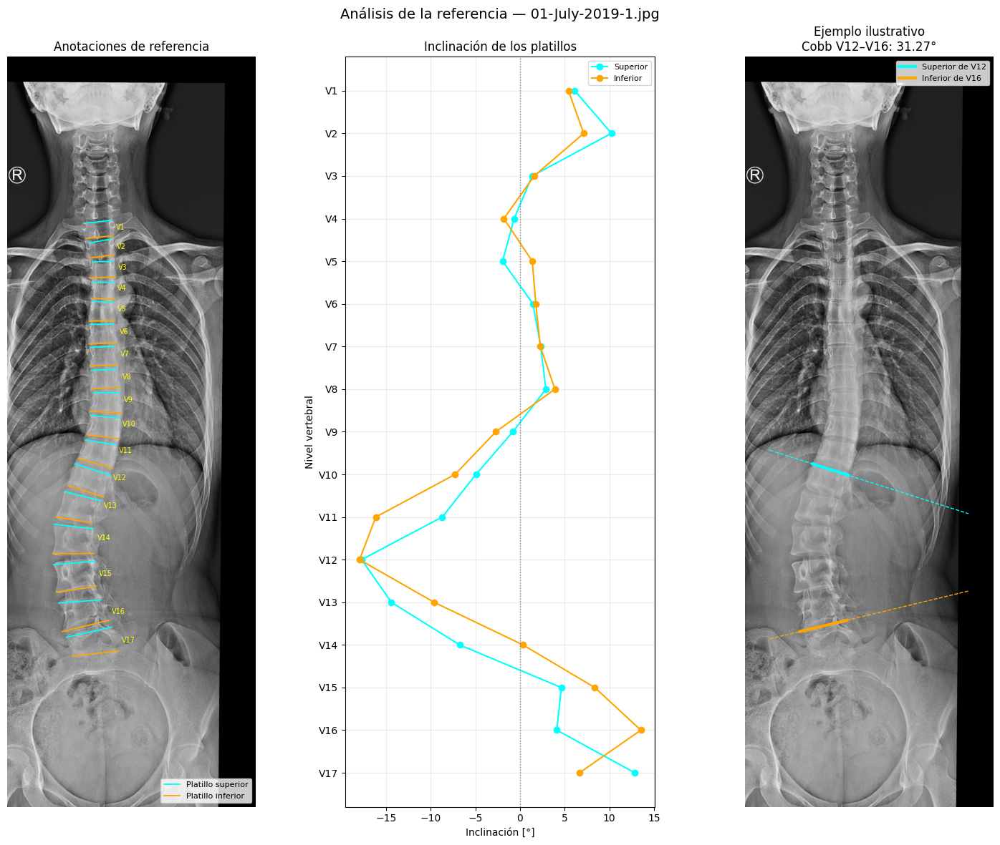

Platillo superior de V12: -17.74°
Platillo inferior de V16: 13.54°
Cobb ilustrativo de referencia: 31.27°


In [7]:
# Referencia utilizada para la evaluación: visualización y análisis

# Seleccionar la radiografía utilizada como ejemplo
INDICE = 0

ruta = imagenes[INDICE]

img_original = cv2.imread(
    str(ruta),
    cv2.IMREAD_GRAYSCALE
)

if img_original is None:
    raise ValueError(
        f"No se pudo leer {ruta.name}"
    )

import io
import urllib.request

# Dirección de las anotaciones publicadas
BASE_REFERENCIAS = (
    "https://raw.githubusercontent.com/"
    "sudaoer/AASCE2019-test98-annotations/"
    "08b3c9cd799ac787ec6a537aace6560afcaa6d0e/"
    "dataset/MICCAI_98_Annotations/"
)

url_referencia = (
    BASE_REFERENCIAS
    + ruta.stem
    + "_corner.pts"
)

# Descargar los puntos de referencia
with urllib.request.urlopen(
    url_referencia,
    timeout=30
) as respuesta:
    texto_referencia = (
        respuesta.read().decode("utf-8")
    )

esquinas_ref = np.loadtxt(
    io.StringIO(texto_referencia)
)

if esquinas_ref.shape != (68, 2):
    raise ValueError(
        "La referencia no contiene los 68 puntos esperados."
    )

# Cada vértebra contiene:
# superior izquierda, superior derecha,
# inferior izquierda e inferior derecha
vertebras_ref = esquinas_ref.reshape(
    17,
    4,
    2
)


# ---------------------------------------------------------
# Inclinación de los platillos
# ---------------------------------------------------------

vectores_sup_ref = (
    vertebras_ref[:, 1]
    - vertebras_ref[:, 0]
)

vectores_inf_ref = (
    vertebras_ref[:, 3]
    - vertebras_ref[:, 2]
)

# Se invierte el eje vertical porque en la imagen
# las coordenadas y aumentan hacia abajo
ang_sup_ref = np.degrees(
    np.arctan2(
        -vectores_sup_ref[:, 1],
        vectores_sup_ref[:, 0]
    )
)

ang_inf_ref = np.degrees(
    np.arctan2(
        -vectores_inf_ref[:, 1],
        vectores_inf_ref[:, 0]
    )
)

niveles_ref = np.arange(1, 18)


# ---------------------------------------------------------
# Ejemplo ilustrativo del cálculo de Cobb
# ---------------------------------------------------------

V_SUP = 12
V_INF = 16

angulo_superior_ref = float(
    ang_sup_ref[V_SUP - 1]
)

angulo_inferior_ref = float(
    ang_inf_ref[V_INF - 1]
)

diferencia_ref = (
    abs(
        angulo_superior_ref
        - angulo_inferior_ref
    )
    % 180
)

cobb_ref = min(
    diferencia_ref,
    180 - diferencia_ref
)


# Tabla disponible para consultar, pero no se muestra
# completa para evitar una salida demasiado extensa
tabla_inclinaciones_ref = pd.DataFrame({
    "Vértebra": [
        f"V{i}"
        for i in niveles_ref
    ],
    "Platillo superior (°)": ang_sup_ref,
    "Platillo inferior (°)": ang_inf_ref,
})


# ---------------------------------------------------------
# Figura integrada
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 12),
    gridspec_kw={
        "width_ratios": [1, 0.8, 1]
    }
)


# Panel 1: todos los platillos de referencia
axes[0].imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255
)

for i, vertebra in enumerate(
    vertebras_ref,
    start=1
):
    axes[0].plot(
        vertebra[:2, 0],
        vertebra[:2, 1],
        color="cyan",
        linewidth=1.3,
        label=(
            "Platillo superior"
            if i == 1
            else None
        )
    )

    axes[0].plot(
        vertebra[2:, 0],
        vertebra[2:, 1],
        color="orange",
        linewidth=1.3,
        label=(
            "Platillo inferior"
            if i == 1
            else None
        )
    )

    axes[0].text(
        vertebra[:, 0].max()
        + 0.012 * img_original.shape[1],
        vertebra[:, 1].mean(),
        f"V{i}",
        color="yellow",
        fontsize=7
    )

axes[0].set_title(
    "Anotaciones de referencia"
)

axes[0].legend(
    fontsize=8,
    loc="lower right"
)

axes[0].axis("off")


# Panel 2: perfil de inclinaciones
axes[1].plot(
    ang_sup_ref,
    niveles_ref,
    "o-",
    color="cyan",
    label="Superior"
)

axes[1].plot(
    ang_inf_ref,
    niveles_ref,
    "o-",
    color="orange",
    label="Inferior"
)

axes[1].axvline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1
)

axes[1].set_yticks(
    niveles_ref
)

axes[1].set_yticklabels([
    f"V{i}"
    for i in niveles_ref
])

axes[1].invert_yaxis()

axes[1].set_xlabel(
    "Inclinación [°]"
)

axes[1].set_ylabel(
    "Nivel vertebral"
)

axes[1].set_title(
    "Inclinación de los platillos"
)

axes[1].grid(
    alpha=0.25
)

axes[1].legend(
    fontsize=8
)


# Panel 3: ejemplo de Cobb de referencia
axes[2].imshow(
    img_original,
    cmap="gray",
    vmin=0,
    vmax=255
)

x_extendida = np.array([
    0.10,
    0.90
]) * img_original.shape[1]

platillos_elegidos = [
    (
        vertebras_ref[V_SUP - 1, :2],
        "cyan",
        f"Superior de V{V_SUP}"
    ),
    (
        vertebras_ref[V_INF - 1, 2:],
        "orange",
        f"Inferior de V{V_INF}"
    ),
]

for platillo, color, etiqueta in (
    platillos_elegidos
):
    dx, dy = (
        platillo[1]
        - platillo[0]
    )

    y_extendida = (
        platillo[0, 1]
        + (dy / (dx + 1e-8))
        * (
            x_extendida
            - platillo[0, 0]
        )
    )

    axes[2].plot(
        x_extendida,
        y_extendida,
        "--",
        color=color,
        linewidth=1
    )

    axes[2].plot(
        platillo[:, 0],
        platillo[:, 1],
        color=color,
        linewidth=3,
        label=etiqueta
    )

axes[2].set_title(
    "Ejemplo ilustrativo\n"
    f"Cobb V{V_SUP}–V{V_INF}: "
    f"{cobb_ref:.2f}°"
)

axes[2].legend(
    fontsize=8
)

axes[2].axis("off")


plt.suptitle(
    f"Análisis de la referencia — {ruta.name}",
    fontsize=14
)

plt.tight_layout()
plt.show()


print(
    f"Platillo superior de V{V_SUP}: "
    f"{angulo_superior_ref:.2f}°"
)

print(
    f"Platillo inferior de V{V_INF}: "
    f"{angulo_inferior_ref:.2f}°"
)

print(
    f"Cobb ilustrativo de referencia: "
    f"{cobb_ref:.2f}°"
)

In [38]:
# 21. Procesamiento de las 98 radiografías y evaluación

import io
import contextlib
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter


# ---------------------------------------------------------
# 1. Recuperar las celdas actuales del procesamiento
# ---------------------------------------------------------

historial = list(
    get_ipython().history_manager.input_hist_raw
)

# Excluir esta misma celda del historial
historial_anterior = historial[:-1]


def buscar_celda(numero, titulo):
    """
    Recupera la última versión ejecutada de una celda
    identificada por su encabezado.
    """

    marcador = (
        "# "
        + str(numero)
        + ". "
        + titulo
    )

    for fuente in reversed(historial_anterior):
        if marcador in fuente:
            return fuente

    raise RuntimeError(
        f"No se encontró la celda {numero}: {titulo}. "
        "Ejecutala una vez y volvé a ejecutar esta celda."
    )


def recortar_visualizacion(fuente, marcadores):
    """
    Elimina solamente la parte de visualización para que
    el procesamiento de 98 imágenes sea más rápido.
    """

    posiciones = []

    for marcador in marcadores:
        posicion = fuente.find(marcador)

        if posicion >= 0:
            posiciones.append(posicion)

    if posiciones:
        fuente = fuente[:min(posiciones)]

    return fuente


fuente_12 = buscar_celda(
    12,
    "Aislamiento de la región de la columna y matriz ósea"
)

fuente_13 = buscar_celda(
    13,
    "Realce de estructuras óseas y platillos"
)

fuente_14 = buscar_celda(
    14,
    "Detección regularizada de 17 niveles vertebrales"
)

fuente_15 = buscar_celda(
    15,
    "Centros candidatos y ajuste polinómico del eje"
)

fuente_17 = buscar_celda(
    17,
    "Ajuste restringido de los platillos vertebrales"
)

fuente_18 = buscar_celda(
    18,
    "Control de calidad de los platillos detectados"
)

fuente_19 = buscar_celda(
    19,
    "Perfil de inclinaciones y selección de vértebras límite"
)


# Quitar gráficos y tablas intermedias
fuente_12 = recortar_visualizacion(
    fuente_12,
    [
        "# Visualización del procedimiento",
        "fig, axes = plt.subplots"
    ]
)

fuente_13 = recortar_visualizacion(
    fuente_13,
    ["fig, axes = plt.subplots"]
)

fuente_14 = recortar_visualizacion(
    fuente_14,
    ["# Visualización"]
)

fuente_15 = recortar_visualizacion(
    fuente_15,
    ["# Visualización"]
)

fuente_17 = recortar_visualizacion(
    fuente_17,
    ["# Visualización"]
)

fuente_18 = recortar_visualizacion(
    fuente_18,
    ["tabla_calidad ="]
)

fuente_19 = recortar_visualizacion(
    fuente_19,
    ["# Tabla de inclinaciones"]
)

fuentes_procesamiento = [
    fuente_12,
    fuente_13,
    fuente_14,
    fuente_15,
    fuente_17,
    fuente_18,
    fuente_19,
]

print(
    "Se recuperaron correctamente las etapas "
    "12, 13, 14, 15, 17, 18 y 19."
)


# ---------------------------------------------------------
# 2. Funciones de Cobb, gravedad y comparación
# ---------------------------------------------------------

def diferencia_aguda(angulo_1, angulo_2):
    """
    Calcula el menor ángulo entre dos rectas.
    """

    diferencia = (
        abs(float(angulo_1) - float(angulo_2))
        % 180
    )

    return min(
        diferencia,
        180 - diferencia
    )


def clasificar_gravedad(cobb):
    """
    Clasificación utilizada en el trabajo.
    """

    if not np.isfinite(cobb):
        return "No disponible"

    if cobb < 10:
        return "Inferior al umbral de 10°"

    if cobb < 25:
        return "Leve"

    if cobb < 40:
        return "Moderada"

    return "Severa"


def angulo_representativo(
    angulos_superiores,
    angulos_inferiores
):
    """
    Combina los dos platillos de cada cuerpo mediante
    una media circular para orientaciones de rectas.
    """

    resultado = []

    for superior, inferior in zip(
        angulos_superiores,
        angulos_inferiores
    ):
        angulos_rad = np.radians([
            superior,
            inferior
        ])

        seno = np.mean(
            np.sin(2 * angulos_rad)
        )

        coseno = np.mean(
            np.cos(2 * angulos_rad)
        )

        resultado.append(
            0.5
            * np.degrees(
                np.arctan2(seno, coseno)
            )
        )

    return np.asarray(
        resultado,
        dtype=float
    )


def seleccionar_curvas_desde_angulos(
    angulos_superiores,
    angulos_inferiores
):
    """
    Aplica el mismo criterio de extremos angulares
    utilizado en la celda 19.
    """

    angulos = angulo_representativo(
        angulos_superiores,
        angulos_inferiores
    )

    cantidad = len(angulos)
    indices = np.arange(cantidad)

    if cantidad >= 5:
        suavizados = savgol_filter(
            angulos,
            window_length=5,
            polyorder=2,
            mode="interp"
        )
    else:
        suavizados = angulos.copy()

    prominencia = max(
        1.5,
        0.12 * np.ptp(suavizados)
    )

    maximos, _ = find_peaks(
        suavizados,
        prominence=prominencia,
        distance=2
    )

    minimos, _ = find_peaks(
        -suavizados,
        prominence=prominencia,
        distance=2
    )

    extremos = np.unique(
        np.concatenate([
            [0],
            maximos,
            minimos,
            [cantidad - 1]
        ])
    )

    curvas = []

    for extremo_1, extremo_2 in zip(
        extremos[:-1],
        extremos[1:]
    ):
        angulo_1 = suavizados[extremo_1]
        angulo_2 = suavizados[extremo_2]

        signo_opuesto = (
            angulo_1 * angulo_2 <= 0
        )

        cambio = abs(
            angulo_2 - angulo_1
        )

        if signo_opuesto and cambio >= 5:
            curvas.append((
                int(extremo_1),
                int(extremo_2)
            ))

    # Respaldo si no se encontraron curvas
    if len(curvas) == 0:
        indice_maximo = int(
            np.argmax(suavizados)
        )

        indice_minimo = int(
            np.argmin(suavizados)
        )

        superior = min(
            indice_maximo,
            indice_minimo
        )

        inferior = max(
            indice_maximo,
            indice_minimo
        )

        if superior != inferior:
            curvas.append((
                superior,
                inferior
            ))

    return curvas


def calcular_cobbs(
    curvas,
    angulos_superiores,
    angulos_inferiores
):
    """
    Calcula Cobb para cada par de vértebras límite.
    """

    resultados = []

    for numero, (superior, inferior) in enumerate(
        curvas,
        start=1
    ):
        cobb = diferencia_aguda(
            angulos_superiores[superior],
            angulos_inferiores[inferior]
        )

        resultados.append({
            "curva": numero,
            "limite_superior": superior + 1,
            "limite_inferior": inferior + 1,
            "cobb": cobb,
            "gravedad": clasificar_gravedad(cobb),
        })

    return resultados


def iou_intervalos(par_1, par_2):
    """
    Superposición entre dos intervalos vertebrales.
    """

    inicio_1, final_1 = par_1
    inicio_2, final_2 = par_2

    interseccion = max(
        0,
        min(final_1, final_2)
        - max(inicio_1, inicio_2)
        + 1
    )

    union = (
        max(final_1, final_2)
        - min(inicio_1, inicio_2)
        + 1
    )

    return interseccion / union


def emparejar_curvas(
    curvas_automaticas,
    curvas_referencia
):
    """
    Empareja curvas según su superposición vertebral.
    """

    candidatos = []

    for indice_auto, curva_auto in enumerate(
        curvas_automaticas
    ):
        for indice_ref, curva_ref in enumerate(
            curvas_referencia
        ):
            candidatos.append((
                iou_intervalos(
                    curva_auto,
                    curva_ref
                ),
                indice_auto,
                indice_ref
            ))

    usados_auto = set()
    usados_ref = set()
    parejas = []

    for superposicion, indice_auto, indice_ref in sorted(
        candidatos,
        reverse=True
    ):
        if superposicion <= 0:
            continue

        if indice_auto in usados_auto:
            continue

        if indice_ref in usados_ref:
            continue

        parejas.append((
            indice_auto,
            indice_ref,
            superposicion
        ))

        usados_auto.add(indice_auto)
        usados_ref.add(indice_ref)

    return parejas, usados_auto, usados_ref


# ---------------------------------------------------------
# 3. Procesamiento automático de una radiografía
# ---------------------------------------------------------

def procesar_automaticamente(ruta_imagen):
    """
    Procesa una radiografía sin consultar su referencia.
    """

    imagen = cv2.imread(
        str(ruta_imagen),
        cv2.IMREAD_GRAYSCALE
    )

    if imagen is None:
        raise ValueError(
            "No se pudo leer la radiografía."
        )

    espacio = dict(globals())

    espacio.update({
        "ruta": ruta_imagen,
        "img_original": imagen,
        "display": lambda *args, **kwargs: None,
    })

    # Evitar mostrar las salidas intermedias
    with contextlib.redirect_stdout(io.StringIO()):
        for fuente in fuentes_procesamiento:
            exec(
                fuente,
                espacio
            )

    plt.close("all")

    angulos_sup = np.asarray(
        espacio["angulos_superiores"],
        dtype=float
    )

    angulos_inf = np.asarray(
        espacio["angulos_inferiores"],
        dtype=float
    )

    curvas = [
        tuple(map(int, curva))
        for curva in espacio[
            "curvas_candidatas"
        ]
    ]

    resultados = calcular_cobbs(
        curvas,
        angulos_sup,
        angulos_inf
    )

    return {
        "curvas": curvas,
        "angulos_superiores": angulos_sup,
        "angulos_inferiores": angulos_inf,
        "resultados": resultados,
        "niveles_confirmados": int(
            np.sum(
                espacio[
                    "ajustado_por_perfil"
                ]
            )
        ),
        "platillos_validos": int(
            np.sum(
                espacio[
                    "platillos_validos"
                ]
            )
        ),
    }


# ---------------------------------------------------------
# 4. Lectura independiente de la referencia
# ---------------------------------------------------------

BASE_REFERENCIAS = (
    "https://raw.githubusercontent.com/"
    "sudaoer/AASCE2019-test98-annotations/"
    "08b3c9cd799ac787ec6a537aace6560afcaa6d0e/"
    "dataset/MICCAI_98_Annotations/"
)


def obtener_referencia(ruta_imagen):
    """
    Descarga las esquinas de referencia después de realizar
    el procesamiento automático.
    """

    url = (
        BASE_REFERENCIAS
        + ruta_imagen.stem
        + "_corner.pts"
    )

    with urllib.request.urlopen(
        url,
        timeout=30
    ) as respuesta:
        texto = respuesta.read().decode(
            "utf-8"
        )

    esquinas = np.loadtxt(
        io.StringIO(texto)
    )

    vertebras = esquinas.reshape(
        17,
        4,
        2
    )

    vectores_sup = (
        vertebras[:, 1]
        - vertebras[:, 0]
    )

    vectores_inf = (
        vertebras[:, 3]
        - vertebras[:, 2]
    )

    # Convención de coordenadas de la imagen
    angulos_sup = np.degrees(
        np.arctan2(
            vectores_sup[:, 1],
            vectores_sup[:, 0]
        )
    )

    angulos_inf = np.degrees(
        np.arctan2(
            vectores_inf[:, 1],
            vectores_inf[:, 0]
        )
    )

    curvas = seleccionar_curvas_desde_angulos(
        angulos_sup,
        angulos_inf
    )

    resultados = calcular_cobbs(
        curvas,
        angulos_sup,
        angulos_inf
    )

    return {
        "curvas": curvas,
        "resultados": resultados,
    }


# ---------------------------------------------------------
# 5. Ejecutar las 98 radiografías
# ---------------------------------------------------------

filas_resultados = []
filas_resumen = []
errores_procesamiento = []

cantidad_imagenes = len(imagenes)

for posicion, ruta_imagen in enumerate(
    imagenes,
    start=1
):
    print(
        f"[{posicion:02d}/{cantidad_imagenes}] "
        f"{ruta_imagen.name}",
        end=" — "
    )

    try:
        # Primero se procesa sin conocer la referencia
        automatico = procesar_automaticamente(
            ruta_imagen
        )

        # Después se obtiene la referencia para evaluar
        referencia = obtener_referencia(
            ruta_imagen
        )

        parejas, usados_auto, usados_ref = emparejar_curvas(
            automatico["curvas"],
            referencia["curvas"]
        )

        filas_resumen.append({
            "archivo": ruta_imagen.name,
            "curvas_automaticas": len(
                automatico["curvas"]
            ),
            "curvas_referencia": len(
                referencia["curvas"]
            ),
            "niveles_confirmados": automatico[
                "niveles_confirmados"
            ],
            "platillos_validos": automatico[
                "platillos_validos"
            ],
            "curvas_emparejadas": len(parejas),
            "estado": "OK",
        })

        # Curvas emparejadas
        for indice_auto, indice_ref, superposicion in parejas:
            resultado_auto = automatico[
                "resultados"
            ][indice_auto]

            resultado_ref = referencia[
                "resultados"
            ][indice_ref]

            error = abs(
                resultado_auto["cobb"]
                - resultado_ref["cobb"]
            )

            filas_resultados.append({
                "archivo": ruta_imagen.name,
                "curva_automatica": (
                    indice_auto + 1
                ),
                "limite_superior_auto": resultado_auto[
                    "limite_superior"
                ],
                "limite_inferior_auto": resultado_auto[
                    "limite_inferior"
                ],
                "cobb_automatico": resultado_auto[
                    "cobb"
                ],
                "gravedad_automatica": resultado_auto[
                    "gravedad"
                ],
                "curva_referencia": (
                    indice_ref + 1
                ),
                "limite_superior_ref": resultado_ref[
                    "limite_superior"
                ],
                "limite_inferior_ref": resultado_ref[
                    "limite_inferior"
                ],
                "cobb_referencia": resultado_ref[
                    "cobb"
                ],
                "gravedad_referencia": resultado_ref[
                    "gravedad"
                ],
                "error_absoluto": error,
                "superposicion_limites": superposicion,
                "coincide_gravedad": (
                    resultado_auto["gravedad"]
                    == resultado_ref["gravedad"]
                ),
                "estado_curva": "Emparejada",
            })

        # Curvas automáticas sin pareja
        for indice_auto, resultado_auto in enumerate(
            automatico["resultados"]
        ):
            if indice_auto in usados_auto:
                continue

            filas_resultados.append({
                "archivo": ruta_imagen.name,
                "curva_automatica": indice_auto + 1,
                "limite_superior_auto": resultado_auto[
                    "limite_superior"
                ],
                "limite_inferior_auto": resultado_auto[
                    "limite_inferior"
                ],
                "cobb_automatico": resultado_auto[
                    "cobb"
                ],
                "gravedad_automatica": resultado_auto[
                    "gravedad"
                ],
                "estado_curva": (
                    "Automática sin referencia emparejada"
                ),
            })

        # Curvas de referencia que no fueron detectadas
        for indice_ref, resultado_ref in enumerate(
            referencia["resultados"]
        ):
            if indice_ref in usados_ref:
                continue

            filas_resultados.append({
                "archivo": ruta_imagen.name,
                "curva_referencia": indice_ref + 1,
                "limite_superior_ref": resultado_ref[
                    "limite_superior"
                ],
                "limite_inferior_ref": resultado_ref[
                    "limite_inferior"
                ],
                "cobb_referencia": resultado_ref[
                    "cobb"
                ],
                "gravedad_referencia": resultado_ref[
                    "gravedad"
                ],
                "estado_curva": (
                    "Referencia no detectada"
                ),
            })

        print("OK")

    except Exception as error:
        mensaje = str(error)

        errores_procesamiento.append({
            "archivo": ruta_imagen.name,
            "error": mensaje,
        })

        filas_resumen.append({
            "archivo": ruta_imagen.name,
            "estado": f"ERROR: {mensaje}",
        })

        print("ERROR:", mensaje)


# ---------------------------------------------------------
# 6. Tablas y métricas finales
# ---------------------------------------------------------

tabla_resultados_98 = pd.DataFrame(
    filas_resultados
)

tabla_resumen_98 = pd.DataFrame(
    filas_resumen
)

tabla_errores_98 = pd.DataFrame(
    errores_procesamiento
)

# Solo curvas que pudieron compararse
comparaciones_validas = tabla_resultados_98[
    tabla_resultados_98["estado_curva"]
    == "Emparejada"
].copy()

mae_cobb = comparaciones_validas[
    "error_absoluto"
].mean()

mediana_error = comparaciones_validas[
    "error_absoluto"
].median()

porcentaje_5_grados = (
    comparaciones_validas[
        "error_absoluto"
    ].le(5).mean() * 100
)

coincidencia_gravedad = (
    comparaciones_validas[
        "coincide_gravedad"
    ].mean() * 100
)

resumen_metricas_98 = pd.DataFrame({
    "Métrica": [
        "Radiografías procesadas correctamente",
        "Radiografías con error",
        "Curvas emparejadas",
        "MAE del ángulo de Cobb",
        "Mediana del error",
        "Mediciones dentro de ±5°",
        "Coincidencia de gravedad",
    ],
    "Resultado": [
        int(
            (tabla_resumen_98["estado"] == "OK").sum()
        ),
        len(tabla_errores_98),
        len(comparaciones_validas),
        f"{mae_cobb:.2f}°",
        f"{mediana_error:.2f}°",
        f"{porcentaje_5_grados:.1f} %",
        f"{coincidencia_gravedad:.1f} %",
    ],
})


# Guardado de resultados
tabla_resultados_98.to_csv(
    "/content/resultados_cobb_98.csv",
    index=False
)

tabla_resumen_98.to_csv(
    "/content/resumen_procesamiento_98.csv",
    index=False
)

resumen_metricas_98.to_csv(
    "/content/metricas_cobb_98.csv",
    index=False
)

if len(tabla_errores_98):
    tabla_errores_98.to_csv(
        "/content/errores_procesamiento_98.csv",
        index=False
    )


print("\nProcesamiento finalizado.")
display(resumen_metricas_98)

print("\nPrimeras comparaciones:")
display(
    comparaciones_validas.head(20).round(2)
)

print(
    "\nArchivos guardados en /content:\n"
    "• resultados_cobb_98.csv\n"
    "• resumen_procesamiento_98.csv\n"
    "• metricas_cobb_98.csv"
)

Se recuperaron correctamente las etapas 12, 13, 14, 15, 17, 18 y 19.
[01/98] 01-July-2019-1.jpg — OK
[02/98] 01-July-2019-10.jpg — OK
[03/98] 01-July-2019-11.jpg — OK
[04/98] 01-July-2019-12.jpg — OK
[05/98] 01-July-2019-13.jpg — OK
[06/98] 01-July-2019-14.jpg — OK
[07/98] 01-July-2019-15.jpg — OK
[08/98] 01-July-2019-16.jpg — OK
[09/98] 01-July-2019-17.jpg — OK
[10/98] 01-July-2019-18.jpg — OK
[11/98] 01-July-2019-19.jpg — OK
[12/98] 01-July-2019-2.jpg — OK
[13/98] 01-July-2019-20.jpg — OK
[14/98] 01-July-2019-21.jpg — OK
[15/98] 01-July-2019-22.jpg — OK
[16/98] 01-July-2019-23.jpg — OK
[17/98] 01-July-2019-24.jpg — OK
[18/98] 01-July-2019-25.jpg — OK
[19/98] 01-July-2019-26.jpg — OK
[20/98] 01-July-2019-27.jpg — OK
[21/98] 01-July-2019-28.jpg — OK
[22/98] 01-July-2019-29.jpg — OK
[23/98] 01-July-2019-3.jpg — OK
[24/98] 01-July-2019-30.jpg — OK
[25/98] 01-July-2019-31.jpg — OK
[26/98] 01-July-2019-32.jpg — OK
[27/98] 01-July-2019-33.jpg — OK
[28/98] 01-July-2019-34.jpg — OK
[29/98] 01

,Métrica,Resultado
0,Radiografías procesadas correctamente,98
1,Radiografías con error,0
2,Curvas emparejadas,170
3,MAE del ángulo de Cobb,10.23°
4,Mediana del error,7.20°
5,Mediciones dentro de ±5°,34.1 %
6,Coincidencia de gravedad,47.6 %



Primeras comparaciones:


,archivo,curva_automatica,limite_superior_auto,limite_inferior_auto,cobb_automatico,gravedad_automatica,curva_referencia,limite_superior_ref,limite_inferior_ref,cobb_referencia,gravedad_referencia,error_absoluto,superposicion_limites,coincide_gravedad,estado_curva
0,01-July-2019-1.jpg,3.0,11.0,17.0,24.48,Leve,3.0,12.0,17.0,24.40,Leve,0.08,0.86,True,Emparejada
1,01-July-2019-1.jpg,2.0,7.0,11.0,24.60,Leve,2.0,7.0,12.0,20.29,Leve,4.30,0.83,True,Emparejada
2,01-July-2019-1.jpg,1.0,3.0,7.0,3.18,Inferior al umbral de 10°,1.0,1.0,4.0,7.94,Inferior al umbral de 10°,4.76,0.29,True,Emparejada
3,01-July-2019-10.jpg,2.0,6.0,12.0,41.73,Severa,2.0,8.0,15.0,16.75,Leve,24.98,0.50,False,Emparejada
4,01-July-2019-10.jpg,1.0,1.0,6.0,16.27,Leve,1.0,4.0,8.0,7.27,Inferior al umbral de 10°,8.99,0.38,False,Emparejada
6,01-July-2019-11.jpg,1.0,1.0,7.0,20.32,Leve,1.0,1.0,7.0,15.85,Leve,4.48,1.00,True,Emparejada
7,01-July-2019-11.jpg,2.0,10.0,12.0,18.88,Leve,2.0,7.0,13.0,23.08,Leve,4.21,0.43,True,Emparejada
9,01-July-2019-12.jpg,2.0,8.0,12.0,8.68,Inferior al umbral de 10°,2.0,8.0,12.0,8.31,Inferior al umbral de 10°,0.37,1.00,True,Emparejada
10,01-July-2019-12.jpg,3.0,12.0,16.0,29.23,Moderada,3.0,12.0,17.0,9.29,Inferior al umbral de 10°,19.94,0.83,False,Emparejada
11,01-July-2019-12.jpg,1.0,1.0,8.0,14.96,Leve,1.0,1.0,5.0,10.45,Leve,4.51,0.62,True,Emparejada



Archivos guardados en /content:
• resultados_cobb_98.csv
• resumen_procesamiento_98.csv
• metricas_cobb_98.csv


In [40]:
# 22. Corrección del diagnóstico por radiografía

comparaciones = tabla_resultados_98[
    tabla_resultados_98["estado_curva"] == "Emparejada"
].copy()

# Recuperar el conjunto si fuera necesario
if "conjunto" not in comparaciones.columns:
    comparaciones["conjunto"] = comparaciones[
        "archivo"
    ].apply(
        lambda nombre: (
            "Calibración"
            if nombre in imagenes_calibracion
            else "Validación"
        )
    )

if "conjunto" not in tabla_resumen_98.columns:
    tabla_resumen_98["conjunto"] = tabla_resumen_98[
        "archivo"
    ].apply(
        lambda nombre: (
            "Calibración"
            if nombre in imagenes_calibracion
            else "Validación"
        )
    )


# Resumen de los errores por imagen
errores_por_imagen = (
    comparaciones
    .groupby(
        ["archivo", "conjunto"],
        as_index=False
    )
    .agg(
        curvas_comparadas=(
            "error_absoluto",
            "size"
        ),
        mae_cobb=(
            "error_absoluto",
            "mean"
        ),
        error_maximo=(
            "error_absoluto",
            "max"
        ),
        dentro_5_porcentaje=(
            "error_absoluto",
            lambda valores: (
                valores.le(5).mean() * 100
            )
        ),
        gravedad_correcta_porcentaje=(
            "coincide_gravedad",
            lambda valores: (
                valores.mean() * 100
            )
        ),
    )
)


diagnostico_imagenes_98 = tabla_resumen_98.merge(
    errores_por_imagen,
    on=["archivo", "conjunto"],
    how="left"
)

# Usar cero cuando no se emparejó ninguna curva
diagnostico_imagenes_98[
    "curvas_comparadas"
] = diagnostico_imagenes_98[
    "curvas_comparadas"
].fillna(0).astype(int)

diagnostico_imagenes_98[
    "falsas_positivas"
] = (
    diagnostico_imagenes_98[
        "curvas_automaticas"
    ]
    - diagnostico_imagenes_98[
        "curvas_comparadas"
    ]
).clip(lower=0)

diagnostico_imagenes_98[
    "curvas_no_detectadas"
] = (
    diagnostico_imagenes_98[
        "curvas_referencia"
    ]
    - diagnostico_imagenes_98[
        "curvas_comparadas"
    ]
).clip(lower=0)


# Peores casos de calibración
peores_calibracion = (
    diagnostico_imagenes_98[
        diagnostico_imagenes_98["conjunto"]
        == "Calibración"
    ]
    .sort_values(
        "mae_cobb",
        ascending=False,
        na_position="first"
    )
    .head(10)
)

print(
    "Peores radiografías de calibración:"
)

display(
    peores_calibracion[[
        "archivo",
        "curvas_automaticas",
        "curvas_referencia",
        "curvas_comparadas",
        "falsas_positivas",
        "curvas_no_detectadas",
        "mae_cobb",
        "error_maximo",
        "gravedad_correcta_porcentaje",
    ]].round(2)
)


# Matriz de confusión
orden_gravedad = [
    "Inferior al umbral de 10°",
    "Leve",
    "Moderada",
    "Severa",
]

matriz_confusion = pd.crosstab(
    comparaciones["gravedad_referencia"],
    comparaciones["gravedad_automatica"],
    rownames=["Referencia"],
    colnames=["Automática"],
    dropna=False
)

matriz_confusion = matriz_confusion.reindex(
    index=orden_gravedad,
    columns=orden_gravedad,
    fill_value=0
)

print("\nMatriz de confusión:")
display(matriz_confusion)


# Errores más grandes entre las curvas emparejadas
peores_curvas = (
    comparaciones
    .sort_values(
        "error_absoluto",
        ascending=False
    )
    .head(15)
)

print("\nCurvas con mayor error:")
display(
    peores_curvas[[
        "archivo",
        "conjunto",
        "limite_superior_auto",
        "limite_inferior_auto",
        "cobb_automatico",
        "gravedad_automatica",
        "limite_superior_ref",
        "limite_inferior_ref",
        "cobb_referencia",
        "gravedad_referencia",
        "error_absoluto",
    ]].round(2)
)


# Guardar diagnóstico
diagnostico_imagenes_98.to_csv(
    "/content/diagnostico_imagenes_98.csv",
    index=False
)

matriz_confusion.to_csv(
    "/content/matriz_confusion_98.csv"
)

peores_curvas.to_csv(
    "/content/peores_curvas_98.csv",
    index=False
)

print(
    "\nDiagnóstico guardado correctamente."
)

Peores radiografías de calibración:


,archivo,curvas_automaticas,curvas_referencia,curvas_comparadas,falsas_positivas,curvas_no_detectadas,mae_cobb,error_maximo,gravedad_correcta_porcentaje
28,01-July-2019-35.jpg,1,2,1,0,1,41.93,41.93,0.0
5,01-July-2019-14.jpg,3,2,2,1,0,34.43,36.91,0.0
60,01-July-2019-64.jpg,1,1,1,0,0,27.03,27.03,0.0
41,01-July-2019-47.jpg,1,1,1,0,0,19.52,19.52,0.0
95,01-July-2019-96.jpg,1,3,1,0,2,18.89,18.89,0.0
22,01-July-2019-3.jpg,2,2,2,0,0,17.06,20.61,0.0
96,01-July-2019-97.jpg,2,3,2,0,1,15.62,22.60,50.0
40,01-July-2019-46.jpg,3,1,1,2,0,11.51,11.51,0.0
58,01-July-2019-62.jpg,2,3,2,0,1,9.10,12.85,100.0
77,01-July-2019-8.jpg,3,2,2,1,0,8.35,11.06,100.0



Matriz de confusión:


Automática,Inferior al umbral de 10°,Leve,Moderada,Severa
Referencia,,,,
Inferior al umbral de 10°,12,10,4,0
Leve,23,56,12,6
Moderada,7,14,12,5
Severa,0,3,5,1



Curvas con mayor error:


,archivo,conjunto,limite_superior_auto,limite_inferior_auto,cobb_automatico,gravedad_automatica,limite_superior_ref,limite_inferior_ref,cobb_referencia,gravedad_referencia,error_absoluto
237,01-July-2019-91.jpg,Validación,10.0,13.0,12.15,Leve,10.0,14.0,55.29,Severa,43.14
71,01-July-2019-35.jpg,Calibración,13.0,15.0,15.02,Leve,10.0,15.0,56.95,Severa,41.93
14,01-July-2019-14.jpg,Calibración,13.0,17.0,1.40,Inferior al umbral de 10°,12.0,17.0,38.31,Moderada,36.91
15,01-July-2019-14.jpg,Calibración,5.0,13.0,30.09,Moderada,8.0,12.0,62.05,Severa,31.96
75,01-July-2019-36.jpg,Validación,11.0,14.0,4.77,Inferior al umbral de 10°,11.0,16.0,36.02,Moderada,31.25
234,01-July-2019-9.jpg,Validación,5.0,13.0,41.33,Severa,4.0,10.0,12.33,Leve,29.00
44,01-July-2019-25.jpg,Validación,13.0,17.0,5.13,Inferior al umbral de 10°,10.0,15.0,32.92,Moderada,27.79
81,01-July-2019-38.jpg,Validación,5.0,13.0,6.55,Inferior al umbral de 10°,6.0,13.0,34.31,Moderada,27.76
118,01-July-2019-5.jpg,Validación,5.0,11.0,1.56,Inferior al umbral de 10°,7.0,14.0,29.11,Moderada,27.55
35,01-July-2019-22.jpg,Validación,2.0,9.0,20.76,Leve,3.0,11.0,48.02,Severa,27.26



Diagnóstico guardado correctamente.


In [41]:
# Guardar los resultados en Google Drive

from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

carpeta_resultados = Path(
    "/content/drive/MyDrive/TPI_Cobb/resultados"
)

carpeta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

archivos_resultados = [
    "resultados_cobb_98.csv",
    "resumen_procesamiento_98.csv",
    "metricas_cobb_98.csv",
    "errores_procesamiento_98.csv",
    "diagnostico_imagenes_98.csv",
    "metricas_calibracion_validacion.csv",
]

for nombre in archivos_resultados:
    origen = Path("/content") / nombre

    if origen.exists():
        shutil.copy2(
            origen,
            carpeta_resultados / nombre
        )

        print("Guardado:", nombre)
    else:
        print("Todavía no existe:", nombre)

print(
    "\nResultados guardados en:",
    carpeta_resultados
)

Mounted at /content/drive
Guardado: resultados_cobb_98.csv
Guardado: resumen_procesamiento_98.csv
Guardado: metricas_cobb_98.csv
Todavía no existe: errores_procesamiento_98.csv
Guardado: diagnostico_imagenes_98.csv
Todavía no existe: metricas_calibracion_validacion.csv

Resultados guardados en: /content/drive/MyDrive/TPI_Cobb/resultados


In [42]:
# 24. Métricas finales por conjunto

filas_metricas_finales = []

for nombre_conjunto in [
    "Calibración",
    "Validación"
]:
    datos = comparaciones[
        comparaciones["conjunto"]
        == nombre_conjunto
    ]

    filas_metricas_finales.append({
        "Conjunto": nombre_conjunto,
        "Radiografías": (
            20
            if nombre_conjunto == "Calibración"
            else 78
        ),
        "Curvas comparadas": len(datos),
        "MAE Cobb (°)": datos[
            "error_absoluto"
        ].mean(),
        "Mediana error (°)": datos[
            "error_absoluto"
        ].median(),
        "Dentro de ±5° (%)": (
            datos["error_absoluto"]
            .le(5)
            .mean()
            * 100
        ),
        "Gravedad correcta (%)": (
            datos["coincide_gravedad"]
            .mean()
            * 100
        ),
    })

metricas_finales = pd.DataFrame(
    filas_metricas_finales
)

display(
    metricas_finales.round(2)
)

metricas_finales.to_csv(
    "/content/metricas_finales.csv",
    index=False
)

,Conjunto,Radiografías,Curvas comparadas,MAE Cobb (°),Mediana error (°),Dentro de ±5° (%),Gravedad correcta (%)
0,Calibración,20,36,11.20,6.83,36.11,61.11
1,Validación,78,134,9.97,7.38,33.58,44.03


Se procesaron correctamente las 98 radiografías mediante técnicas clásicas de procesamiento digital, sin utilizar modelos de machine learning. Se reservaron 20 imágenes para calibración y 78 para validación. En el conjunto de validación se compararon 134 curvas emparejadas, obteniéndose un error absoluto medio de 9,97°, una mediana de 7,38° y un 33,58 % de mediciones dentro de una tolerancia de ±5°. La clasificación de gravedad coincidió con la referencia en el 44,03 % de las curvas emparejadas.  

El análisis de los errores mostró que las mayores diferencias se producen cuando el método selecciona incorrectamente las vértebras límite o cuando los bordes de costillas y otras estructuras interfieren con la estimación de los platillos. También se observó una tendencia a clasificar curvas moderadas y severas como leves. Por lo tanto, el procedimiento constituye una prueba de concepto funcional, pero sus resultados aún no permiten considerarlo un método de uso clínico. Las anotaciones de la base de datos se utilizaron exclusivamente para evaluar el procesamiento automático.